# Proyecto ML - Parte 2

Jose Manuel Fonseca - 202122456  
Julian Pinto -  
Daniel Vergara -

## Contexto y objetivo

Vamos a clasificar reseñas en español, inglés, portugués, francés y mezclas como positivas, negativas o neutrales. Tenemos 20.466 reseñas etiquetadas y 6.781 de evaluación.

Comparamos cinco redes y un ensamble con la misma validación. Usamos accuracy, F1 macro y errores por idioma. El aumento solo se aplica al entrenamiento. Los experimentos se ejecutan en Colab y sus resultados se guardan en Drive.


## Del equipo local a Colab

Los tres primeros envíos se entrenaron en el computador local. Pasamos a Colab para aprovechar una GPU NVIDIA L4, reducir el tiempo de entrenamiento y guardar avances en Drive. Los cuatro envíos `submission_v1_01.csv` a `submission_v1_04.csv` corresponden a las nuevas corridas en Colab.

Colab permite hacer más trabajo dentro del tiempo disponible, pero el computador local también puede entrenar más épocas. La GPU no mejora el score por sí sola. Conservamos la parada temprana y elegimos la época de menor pérdida de validación. Los límites actuales son 30 épocas para MLP, 6 para MiniLM y 4 para XLM-R; se eligieron las épocas 20, 2, 2 y 2. No afirmamos que se hayan aumentado las épocas respecto a las corridas locales sin comparar sus configuraciones completas.

| Modelo | Score local original | Score Colab v1 | Cambio en puntos porcentuales |
|---|---:|---:|---:|
| MiniLM fijo + MLP | 0.70923 | 0.71611 | +0.688 |
| MiniLM sin aumento | 0.85707 | 0.86149 | +0.442 |
| MiniLM con aumento | 0.85903 | 0.85265 | -0.638 |
| XLM-R por capas | Sin envío local completo | 0.87524 | No comparable |

Estos cambios describen corridas diferentes; no aíslan el efecto de la GPU. Los scores públicos corresponden a la captura de Kaggle y son distintos de las métricas de validación. Conservamos los CSV originales subidos y añadimos nombres descriptivos terminados en `_colab.csv`, con exactamente las mismas predicciones.

## Preparar Colab

Seleccionar una GPU en **Entorno de ejecución → Cambiar tipo de entorno de ejecución**. Una T4 sirve para estos modelos. La siguiente celda prepara las dependencias y monta Drive; no entrena redes.

Los CSV y el notebook deben estar en la carpeta `ISIS-2611-Proyecto-Parte-2-Colab` de Mi unidad. Los datos se copian al disco de Colab para leerlos rápido. Los checkpoints, resultados y modelos se guardan en Drive.

In [36]:
import sys
from pathlib import Path

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    import subprocess
    from importlib.metadata import version, PackageNotFoundError
    requeridas={'transformers':'4.57.3','tokenizers':'0.22.2','huggingface-hub':'0.36.2','langid':'1.1.6'}
    modulos={'transformers':'transformers','tokenizers':'tokenizers','huggingface-hub':'huggingface_hub','langid':'langid'}
    antes={}
    for nombre in requeridas:
        try:antes[nombre]=version(nombre)
        except PackageNotFoundError:antes[nombre]=None
    subprocess.run([sys.executable,'-m','pip','install','-q',*[f'{p}=={v}' for p,v in requeridas.items()]],check=True)
    cambiadas=[p for p in requeridas if modulos[p] in sys.modules and antes[p]!=version(p)]
    if cambiadas:
        raise RuntimeError(f'Reiniciar la sesión y ejecutar otra vez: cambiaron librerías cargadas {cambiadas}.')
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA_PROYECTO=Path('/content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab')
    CARPETA_LOCAL=Path('/content/isis2611_parte2_colab')
else:
    import tempfile
    CARPETA_PROYECTO=Path.cwd()
    CARPETA_LOCAL=Path(tempfile.gettempdir())/'isis2611_parte2_colab_revision'
    print('Revisión local. Los entrenamientos de esta copia se ejecutan en Colab con CUDA.')
CARPETA_LOCAL.mkdir(parents=True,exist_ok=True)
print('Proyecto persistente:',CARPETA_PROYECTO)
print('Trabajo temporal:',CARPETA_LOCAL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proyecto persistente: /content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab
Trabajo temporal: /content/isis2611_parte2_colab


## Imports

Usamos pandas y NumPy para revisar los datos, Matplotlib para las figuras y PyTorch con Transformers para las redes. Las métricas se calculan con scikit-learn.

In [37]:
from pathlib import Path
from contextlib import nullcontext
from functools import partial
from importlib.metadata import version
import copy
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import tempfile
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from huggingface_hub import snapshot_download
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEMILLA=42
MAX_TOKENS=256
ETIQUETAS=['negativo','neutral','positivo']
torch.set_num_threads(2)
os.environ['TOKENIZERS_PARALLELISM']='false'
os.environ['HF_HUB_DISABLE_XET']='1'
DISPOSITIVO='cuda' if torch.cuda.is_available() else 'cpu'
ENTORNO={p:version(p) for p in ['torch','transformers','tokenizers','huggingface-hub','numpy','pandas','scikit-learn','scipy','matplotlib','langid']}
ENTORNO.update(Python=platform.python_version(),CUDA=torch.version.cuda,
    GPU=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
display(pd.Series(ENTORNO,name='Entorno de esta ejecución'))

,Entorno de esta ejecución
torch,2.14.1+cu130
transformers,4.57.3
tokenizers,0.22.2
huggingface-hub,0.36.2
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
scipy,1.16.3
matplotlib,3.10.0
langid,1.1.6


## Configuración general

Run all recorre las secciones en orden. Cada modelo tiene su planteamiento, configuración, entrenamiento, evaluación, submission y conclusión. Los resultados guardados se recuperan; solo se entrenan modelos pendientes con `ENTRENAR=True`.

`GENERAR_SUBMISSION=True` prepara los archivos que falten dentro de cada sección. Los modelos y CSV completos se conservan. Para consultar sin entrenar ni exportar, dejamos ambos controles en `False`. Si cambiamos datos o parámetros usamos otra `VERSION_CORRIDA`.

In [38]:
VERSION_CORRIDA='v1'
ENTRENAR=True
GENERAR_SUBMISSION=True

if not re.fullmatch(r'[A-Za-z0-9_-]+',VERSION_CORRIDA):
    raise ValueError('Revisar el experimento y el nombre de la versión.')
if (ENTRENAR or GENERAR_SUBMISSION) and (not EN_COLAB or DISPOSITIVO!='cuda'):
    raise RuntimeError('Abrir en Colab y seleccionar una GPU antes de entrenar o generar el envío.')
MINILM=dict(nombre='sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2',
    revision='e8f8c211226b894fcb81acc59f3b34ba3efd5f42',licencia='Apache-2.0')
XLMR=dict(nombre='FacebookAI/xlm-roberta-base',revision='e73636d4f797dec63c3081bb6ed5c7b0bb3f2089',licencia='MIT')
HUELLAS_ESPERADAS={'train.csv': '23af8502589d7e7f36dcc3d82d7a8e69d7ba8df4b5f2ac8851ab210f0895002c', 'eval.csv': '878f7d99f339bbcece5c7c587245a1a0349d787161e4196cdbdfd3eff5543818', 'sample_submission.csv': 'edfd4e7df22a92dd126192e6428992e9d4c7a8ec42617cb19469491a6bcc4546', 'particiones.csv': '6e6d9aad443cf22569aefa0e06609ad7ba64273963b3f3df83d79c4dde506401'}
print('Versión:',VERSION_CORRIDA)
print('Entrenar:',ENTRENAR,'| Generar submission:',GENERAR_SUBMISSION)

# Cada sección registra aquí su base y sus hiperparámetros.
BASES={}
CONFIGURACIONES={}

NOMBRES_SUBMISSION={}
# Scores de la captura: solo se asignan al mismo CSV de la corrida v1.
SCORES_KAGGLE_COLAB={1: {'score': 0.71611, 'archivo_subido': 'submission_v1_01.csv', 'sha256': '8bcf98d83cdfa1351fcf10fd3de1b55be66c77193c74c05026828b0df20a30d6'}, 2: {'score': 0.86149, 'archivo_subido': 'submission_v1_02.csv', 'sha256': 'c7f8cf9d658f0f8e207dd853133dc2bd8dfb3ad8e6c38aa2e9fc8af50076ae09'}, 3: {'score': 0.85265, 'archivo_subido': 'submission_v1_03.csv', 'sha256': 'efa62ad424e3212d5ac41641efd382ca69800485138393f027b75157a31f5403'}, 4: {'score': 0.87524, 'archivo_subido': 'submission_v1_04.csv', 'sha256': '5be2615c549e4be67e487f19ae99a552da921b5821c18415c86256972743989d'}}


Versión: v1
Entrenar: True | Generar submission: True


## Cargar datos

Comprobamos las huellas para usar los mismos archivos y evitar lecturas vacías. El modelo recibe `text`; `id` sirve para conservar el orden de las predicciones.

In [39]:
CARPETA_DATOS=CARPETA_LOCAL/'datos'
CARPETA_DATOS.mkdir(exist_ok=True)
for nombre,esperado in HUELLAS_ESPERADAS.items():
    origen=CARPETA_PROYECTO/nombre
    if not origen.is_file():
        raise FileNotFoundError(f'Falta {nombre} en {CARPETA_PROYECTO}.')
    contenido=origen.read_bytes()
    if not contenido or hashlib.sha256(contenido).hexdigest()!=esperado:
        raise ValueError(f'{nombre} está vacío o no corresponde a los datos verificados del proyecto.')
    destino=CARPETA_DATOS/nombre
    if not destino.exists() or hashlib.sha256(destino.read_bytes()).hexdigest()!=esperado:
        destino.write_bytes(contenido)
train=pd.read_csv(CARPETA_DATOS/'train.csv')
eval_df=pd.read_csv(CARPETA_DATOS/'eval.csv')
plantilla=pd.read_csv(CARPETA_DATOS/'sample_submission.csv')
particiones=pd.read_csv(CARPETA_DATOS/'particiones.csv')
assert train.shape==(20466,3) and eval_df.shape==(6781,2) and plantilla.shape==(6781,2)
assert set(train.columns)=={'id','text','label'} and set(eval_df.columns)=={'id','text'}
assert list(plantilla.columns)==['id','answer']
assert train['label'].isin(ETIQUETAS).all()
assert train['id'].notna().all() and train['id'].is_unique
assert eval_df['id'].notna().all() and eval_df['id'].is_unique
assert eval_df['id'].tolist()==plantilla['id'].tolist()
LICENCIAS={nombre:(CARPETA_PROYECTO/nombre).read_text() for nombre in ['LICENSE_MODELOS_APACHE-2.0.txt','LICENSE_XLMR_MIT.txt']}
display(pd.DataFrame({'Archivo':['train','eval'],'Filas':[len(train),len(eval_df)],'Columnas':[len(train.columns),len(eval_df.columns)]}))
display(train.head())

,Archivo,Filas,Columnas
0,train,20466,3
1,eval,6781,2


,id,text,label
0,0,Lo pedí un martes por internet y llegó al terc...,negativo
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo
2,2,Lo compré hace como dos meses en una tienda de...,neutral
3,3,Le routeur capte très bien dans toute la maiso...,negativo
4,4,"I got it a while back on sale online, it arriv...",neutral


## Exploración de los datos

Revisamos nulos, textos vacíos, duplicados, identificadores y distribución de etiquetas. Conservamos los nombres de las columnas y los textos originales.

,train,eval
Valores nulos,0,0
Textos vacíos,0,0
IDs repetidos,0,0
Textos repetidos,0,0


,Cantidad,Proporción
label,,
positivo,7486,0.3658
negativo,7381,0.3606
neutral,5599,0.2736


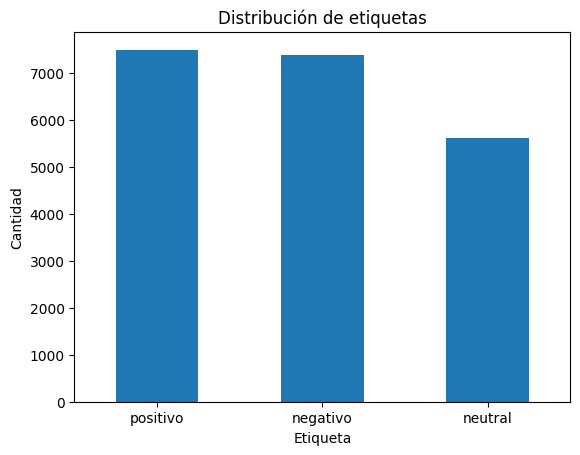

In [40]:
revision=pd.DataFrame({
    'train':[train.isna().sum().sum(),train['text'].str.strip().eq('').sum(),train['id'].duplicated().sum(),train['text'].duplicated().sum()],
    'eval':[eval_df.isna().sum().sum(),eval_df['text'].str.strip().eq('').sum(),eval_df['id'].duplicated().sum(),eval_df['text'].duplicated().sum()],
},index=['Valores nulos','Textos vacíos','IDs repetidos','Textos repetidos'])
display(revision)
assert train.notna().all().all() and eval_df.notna().all().all()
assert train['text'].str.strip().ne('').all() and eval_df['text'].str.strip().ne('').all()
distribucion=train['label'].value_counts().to_frame('Cantidad')
distribucion['Proporción']=train['label'].value_counts(normalize=True).round(4)
display(distribucion)
distribucion['Cantidad'].plot(kind='bar',rot=0,title='Distribución de etiquetas',xlabel='Etiqueta',ylabel='Cantidad')
plt.show()

## Longitudes y ejemplos

La longitud ayuda a elegir un límite de tokens razonable. Leemos ejemplos de la parte de entrenamiento para reconocer opiniones mezcladas, negaciones y veredictos al inicio o al final.

In [41]:
longitudes=train['text'].str.split().str.len()
display(train.assign(palabras=longitudes).groupby('label')['palabras'].agg(['count','mean','median','min','max']).round(2))
print('Textos idénticos entre train y eval:',train['text'].isin(eval_df['text']).sum())
for etiqueta in ETIQUETAS:
    print('\n---',etiqueta.upper(),'---')
    candidatas=particiones['particion'].eq('entrenamiento')&train['label'].eq(etiqueta)
    for texto in train.loc[candidatas,'text'].head(2):
        print(texto,'\n')

,count,mean,median,min,max
label,,,,,
negativo,7381,59.04,58.0,6,125
neutral,5599,53.16,53.0,3,100
positivo,7486,59.10,59.0,5,120


Textos idénticos entre train y eval: 0

--- NEGATIVO ---
Lo pedí un martes por internet y llegó al tercer día, viene en color negro. La resistencia al agua se sintió sobresaliente al final de cuentas. Lo he traído a diario desde entonces. A fin de cuentas, el rendimiento luce ordinario hasta ahora. 

Le routeur capte très bien dans toute la maison, le signal passe même à l'étage sans coupure, c'est franchement solide. Par contre l'application de configuration est une vraie galère, tout est mal traduit et j'ai mis deux heures à brancher correctement les deux bandes. Du coup je ne sais pas trop quoi en penser, d'un côté ça marche bien au quotidien, de l'autre l'installation m'a vraiment agacé. Je vais encore attendre quelques semaines avant de me faire une opinion définitive. 


--- NEUTRAL ---
Lo compré hace como dos meses en una tienda de electrodomésticos del barrio y desde entonces lo uso a diario. Funciona con corriente de 220 voltios, ojo con eso antes de conectarlo. Vi que está di

## Entrenamiento y validación

Conservamos la partición publicada: 16.373 reseñas para ajustar y 4.093 para validar. Los grupos de reseñas muy parecidas permanecen juntos. El archivo incluye los idiomas estimados con langid 1.1.6 y permite repetir la misma comparación.

Las etiquetas de validación se usan para elegir la época, por lo que no es una prueba ciega. `eval` se usa únicamente para generar predicciones. No cambiamos la partición al cambiar de modelo.

In [42]:
assert particiones['id'].tolist()==train['id'].tolist()
assert particiones['label'].tolist()==train['label'].tolist()
assert particiones['sha256_train'].eq(HUELLAS_ESPERADAS['train.csv']).all()
assert set(particiones['particion'])=={'entrenamiento','validacion'}
assert particiones.groupby('grupo')['particion'].nunique().max()==1
INDICES_TRAIN=np.flatnonzero(particiones['particion'].eq('entrenamiento'))
INDICES_VALID=np.flatnonzero(particiones['particion'].eq('validacion'))
assert len(INDICES_TRAIN)==16373 and len(INDICES_VALID)==4093
assert set(INDICES_TRAIN).isdisjoint(INDICES_VALID)
def clave_grupo(texto):
    t=unicodedata.normalize('NFKD',texto.casefold())
    t=''.join(c for c in t if not unicodedata.combining(c))
    return ' '.join(re.findall(r'[^\W_]+',t,flags=re.UNICODE))
claves=train['text'].map(clave_grupo)
assert set(claves.iloc[INDICES_TRAIN]).isdisjoint(claves.iloc[INDICES_VALID])
display(pd.crosstab(particiones['particion'],train['label']))
display(particiones.groupby('grupo').size().value_counts().sort_index().to_frame('Grupos'))
display(pd.crosstab(particiones['idioma_estimado'],particiones['particion']))

label,negativo,neutral,positivo
particion,,,
entrenamiento,5905,4479,5989
validacion,1476,1120,1497


,Grupos
1,20460
2,3


particion,entrenamiento,validacion
idioma_estimado,,
en,1880,470
es,10800,2700
es_en_probable,90,22
fr,1658,414
incierto,36,10
otra_mezcla_probable,62,15
pt,1847,462


## Idiomas y observaciones

Los idiomas son estimados, no etiquetas oficiales. El detector combina langid con pistas de palabras y segmentos para identificar mezclas. Los grupos pequeños se interpretan con cautela.

No quitamos tildes ni negaciones para entrenar. Algunas reseñas mezclan críticas y elogios; por eso la red debe considerar el contexto, no una sola palabra.

In [43]:
import re
import unicodedata
from functools import lru_cache
from importlib.metadata import version
from threadpoolctl import threadpool_limits
from langid.langid import LanguageIdentifier, model

assert version('langid') == '1.1.6', 'Usar langid 1.1.6 para reproducir esta deteccion'
detector_idioma = LanguageIdentifier.from_modelstring(model, norm_probs=True)
detector_idioma.set_languages(['es', 'en', 'pt', 'fr'])
UMBRAL_IDIOMA = 0.80
UMBRAL_SEGMENTO = 0.90
PALABRAS_INGLES = {
    'the', 'this', 'that', 'with', 'was', 'were', 'would', 'have', 'has',
    'had', 'my', 'your', 'their', 'they', 'never', 'honestly', 'actually',
    'expected', 'disappointed', 'wife', 'husband', 'because', 'although',
    'however', 'really', 'works', 'worth', 'bought', 'returned',
    'crispy', 'wings', 'basket', 'dishwasher', 'coating', 'earbuds',
    'pairing', 'bass', 'full', 'phone', 'setup', 'sharp', 'crashing',
    'though', 'still', 'review', 'deal', 'battery', 'screen', 'broken',
}

@lru_cache(maxsize=100000)
def identificar_fragmento(texto):
    idioma, puntuacion = detector_idioma.classify(texto)
    return idioma, float(puntuacion)

def estimar_idioma(texto):
    dominante, puntuacion = identificar_fragmento(texto)
    partes = re.split(r'[.!?;]+', texto)
    segmentos = [p.strip() for p in partes if len(p.split()) >= 8]
    detectados = {
        idioma for segmento in segmentos
        for idioma, valor in [identificar_fragmento(segmento)]
        if valor >= UMBRAL_SEGMENTO
    }
    palabras = re.findall(r"[a-z]+", texto.casefold())
    pistas = [p for p in palabras if p in PALABRAS_INGLES]
    mezcla_segmentos = {'es', 'en'}.issubset(detectados)
    mezcla_palabras = dominante == 'es' and len(set(pistas)) >= 3 and len(pistas) >= 4
    mixta = mezcla_segmentos or mezcla_palabras
    if mixta:
        grupo = 'es_en_probable'
    elif len(detectados) > 1:
        grupo = 'otra_mezcla_probable'
    else:
        grupo = dominante if puntuacion >= UMBRAL_IDIOMA and len(texto.split()) >= 8 else 'incierto'
    return {
        'idioma_dominante': dominante,
        'puntuacion_idioma': puntuacion,
        'idioma_estimado': grupo,
        'mezcla_segmentos': mezcla_segmentos,
        'mezcla_palabras': mezcla_palabras,
    }


columnas_idioma=['idioma_dominante','puntuacion_idioma','idioma_estimado','mezcla_segmentos','mezcla_palabras']
idiomas_train=particiones[columnas_idioma].copy()
with threadpool_limits(limits=1):
    idiomas_eval=pd.DataFrame([estimar_idioma(t) for t in eval_df['text']])
tabla_idiomas=pd.concat({'train':idiomas_train['idioma_estimado'].value_counts(),
    'eval':idiomas_eval['idioma_estimado'].value_counts()},axis=1).fillna(0).astype(int)
tabla_idiomas['train %']=(100*tabla_idiomas['train']/len(train)).round(2)
tabla_idiomas['eval %']=(100*tabla_idiomas['eval']/len(eval_df)).round(2)
display(tabla_idiomas)

,train,eval,train %,eval %
idioma_estimado,,,,
es,13500,4048,65.96,59.70
en,2350,927,11.48,13.67
pt,2309,911,11.28,13.43
fr,2072,796,10.12,11.74
es_en_probable,112,59,0.55,0.87
otra_mezcla_probable,77,34,0.38,0.50
incierto,46,6,0.22,0.09


## Funciones para las redes

Los cuatro modelos comparten el mismo flujo. El primero usa representaciones fijas y una MLP; el segundo y tercero ajustan MiniLM; el cuarto usa XLM-RoBERTa y deja fijos sus embeddings.

Completamos cada lote hasta su mayor longitud y acumulamos gradientes por número de reseñas. CUDA usa precisión mixta al entrenar. Las métricas se calculan en modo de evaluación, sin dropout.

In [44]:
def guardar_atomico(objeto, destino, *, formato='torch'):
    """Primero escribe en el disco local y después publica la copia completa en Drive."""
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=CARPETA_LOCAL) as carpeta:
        local = Path(carpeta) / destino.name
        if formato == 'json':
            local.write_text(json.dumps(objeto, ensure_ascii=False, indent=2))
        else:
            torch.save(objeto, local)
        parcial = destino.with_name(destino.name + '.parcial')
        try:
            shutil.copyfile(local, parcial)
            os.replace(parcial, destino)
        finally:
            parcial.unlink(missing_ok=True)


def rutas_experimento(numero):
    prefijo = f'{VERSION_CORRIDA}_{numero:02d}'
    return {
        'resultado': CARPETA_PROYECTO / f'resultados_{prefijo}.json',
        'desarrollo': CARPETA_PROYECTO / f'checkpoint_{prefijo}_desarrollo.pt',
        'final': CARPETA_PROYECTO / f'checkpoint_{prefijo}_final.pt',
        'modelo': CARPETA_PROYECTO / f'modelo_{prefijo}.pt',
        'submission': CARPETA_PROYECTO / 'submissions' / NOMBRES_SUBMISSION.get(numero,f'submission_{prefijo}.csv'),
        'submission_original': CARPETA_PROYECTO / 'submissions' / f'submission_{prefijo}.csv',
    }


def firma_experimento(numero):
    return dict(protocolo='parte2_colab_v1', experimento=numero, semilla=SEMILLA, max_tokens=MAX_TOKENS,
        etiquetas=ETIQUETAS, base=BASES[numero], configuracion=CONFIGURACIONES[numero],
        datos=HUELLAS_ESPERADAS, aumento=REGLAS_AUMENTO_03 if numero == 3 else None,
        prob_aumento=PROB_AUMENTO_03 if numero == 3 else 0.0, texto='original_con_tildes')


def sembrar(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)


class RedResenas(nn.Module):
    def __init__(self, encoder, numero, configuracion):
        super().__init__()
        self.encoder, self.numero = encoder, numero
        self.cfg = dict(configuracion)
        if self.cfg.get('gradient_checkpointing',False):
            encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
        dimension = encoder.config.hidden_size
        dropout = self.cfg['dropout']
        if numero == 1:
            encoder.requires_grad_(False)
            self.cabeza = nn.Sequential(nn.Linear(dimension,256),nn.ReLU(),nn.Dropout(dropout),
                nn.Linear(256,128),nn.ReLU(),nn.Dropout(dropout),nn.Linear(128,len(ETIQUETAS)))
        elif numero in (4,6):
            encoder.embeddings.requires_grad_(False)
            self.cabeza = nn.Sequential(nn.Dropout(dropout),nn.Linear(dimension,dimension),
                nn.Tanh(),nn.Dropout(dropout),nn.Linear(dimension,len(ETIQUETAS)))
        else:
            self.cabeza = nn.Sequential(nn.Dropout(dropout),nn.Linear(dimension,len(ETIQUETAS)))

    def representar(self, input_ids, attention_mask):
        salida = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        if self.numero in (4,6):
            return salida[:,0]
        mascara = attention_mask.unsqueeze(-1).to(salida.dtype)
        vector = (salida*mascara).sum(1)/mascara.sum(1).clamp(min=1)
        return nn.functional.normalize(vector,p=2,dim=1) if self.numero == 1 else vector

    def forward(self, input_ids=None, attention_mask=None, vectores=None):
        if vectores is None:
            vectores = self.representar(input_ids,attention_mask)
        return self.cabeza(vectores)


def obtener_base(numero):
    base = BASES[numero]
    return snapshot_download(base['nombre'], revision=base['revision'],
        allow_patterns=['config.json','model.safetensors','tokenizer.json','tokenizer_config.json',
                        'special_tokens_map.json','sentencepiece.bpe.model','vocab.txt'])


def construir_red(numero, carpeta_base):
    sembrar(SEMILLA)
    encoder = AutoModel.from_pretrained(carpeta_base,local_files_only=True,
        trust_remote_code=False,add_pooling_layer=False,attn_implementation='sdpa')
    if encoder.config.is_decoder:
        raise ValueError('Solo se utilizan encoders para clasificación.')
    return RedResenas(encoder,numero,CONFIGURACIONES[numero])


class DatosTexto(Dataset):
    def __init__(self, entradas, etiquetas=None, *, vectores=False, variantes=None, semilla=42):
        if len(entradas)==0 or (etiquetas is not None and len(entradas)!=len(etiquetas)):
            raise ValueError('Revisar entradas y etiquetas.')
        if variantes is not None and len(variantes)!=len(entradas):
            raise ValueError('Las variantes deben corresponder a sus originales.')
        self.entradas,self.etiquetas,self.vectores = entradas,etiquetas,vectores
        self.variantes,self.semilla = variantes,semilla
        self.elegibles = np.array([a!=b for a,b in zip(entradas,variantes)]) if variantes is not None else np.zeros(len(entradas),dtype=bool)
        self.usar_variante = np.zeros(len(entradas),dtype=bool)

    def fijar_epoca(self, epoca):
        azar = np.random.default_rng(np.random.SeedSequence([self.semilla,epoca]))
        self.usar_variante = (azar.random(len(self))<PROB_AUMENTO_03)&self.elegibles

    def __len__(self):
        return len(self.entradas)

    def __getitem__(self,i):
        entrada = self.variantes[i] if self.usar_variante[i] else self.entradas[i]
        item = {'vectores' if self.vectores else 'input_ids':entrada}
        if self.etiquetas is not None:
            item['labels'] = int(self.etiquetas[i])
        return item


def completar_lote(filas, pad_id):
    if 'vectores' in filas[0]:
        lote = {'vectores':torch.stack([torch.as_tensor(x['vectores'],dtype=torch.float32) for x in filas])}
    else:
        largo = math.ceil(max(len(x['input_ids']) for x in filas)/8)*8
        ids = torch.full((len(filas),largo),pad_id,dtype=torch.long)
        mascara = torch.zeros_like(ids)
        for i,x in enumerate(filas):
            ids[i,:len(x['input_ids'])] = torch.tensor(x['input_ids'],dtype=torch.long)
            mascara[i,:len(x['input_ids'])] = 1
        lote = {'input_ids':ids,'attention_mask':mascara}
    if 'labels' in filas[0]:
        lote['labels'] = torch.tensor([x['labels'] for x in filas],dtype=torch.long)
    return lote


def crear_lotes(datos, numero, tokenizador, *, entrenamiento=False, generador=None):
    cfg = CONFIGURACIONES[numero]
    return DataLoader(datos,batch_size=cfg['batch_size'] if entrenamiento else cfg['eval_batch_size'],
        shuffle=entrenamiento,generator=generador,num_workers=0,
        collate_fn=partial(completar_lote,pad_id=tokenizador.pad_token_id))


def predecir(red, datos, numero, tokenizador):
    dispositivo = next(red.parameters()).device
    red.eval()
    partes,perdidas,total = [],[],0
    lotes = crear_lotes(datos,numero,tokenizador)
    with torch.inference_mode():
        for paso,lote in enumerate(lotes,1):
            etiquetas = lote.pop('labels',None)
            logits = red(**{k:v.to(dispositivo) for k,v in lote.items()}).float()
            partes.append(logits.softmax(1).cpu())
            if etiquetas is not None:
                perdidas.append(nn.functional.cross_entropy(logits,etiquetas.to(dispositivo),reduction='sum').cpu())
                total += len(etiquetas)
            if paso==1 or paso%100==0:
                print(f'Inferencia: lote {paso}/{len(lotes)}',flush=True)
    probabilidades = torch.cat(partes).numpy()
    if not np.isfinite(probabilidades).all():
        raise FloatingPointError('La red produjo probabilidades no finitas.')
    perdida = torch.stack(perdidas).cpu().double().sum().item()/total if total else None
    return probabilidades,perdida


def grupos_optimizador(red, numero):
    cfg = CONFIGURACIONES[numero]
    grupos = {}
    profundidad = red.encoder.config.num_hidden_layers
    for nombre,parametro in red.named_parameters():
        if not parametro.requires_grad:
            continue
        capa = re.search(r'encoder\.layer\.(\d+)\.',nombre)
        if nombre.startswith('cabeza.'):
            lr = cfg['lr_head']
        elif numero==4 and capa:
            lr = cfg['lr_encoder']*cfg['layer_decay']**(profundidad-1-int(capa[1]))
        else:
            lr = cfg['lr_encoder']
        decay = 0.0 if nombre.endswith('bias') or 'layernorm' in nombre.lower() else cfg['weight_decay']
        grupos.setdefault((lr,decay),[]).append(parametro)
    return [dict(params=ps,lr=lr,weight_decay=wd) for (lr,wd),ps in grupos.items()]

### Entrenar y guardar avances

Cada modelo utiliza estas funciones comunes. Guardamos pesos, optimizador y estados aleatorios después de cada época. La parada temprana recupera la época de menor pérdida de validación; una sesión interrumpida puede continuar desde su checkpoint.

In [45]:
def a_cpu(objeto):
    if torch.is_tensor(objeto):
        return objeto.detach().cpu().clone()
    if isinstance(objeto,dict):
        return {k:a_cpu(v) for k,v in objeto.items()}
    if isinstance(objeto,list):
        return [a_cpu(v) for v in objeto]
    if isinstance(objeto,tuple):
        return tuple(a_cpu(v) for v in objeto)
    return objeto


def pesos_ajustables(red):
    return {n:p.detach().cpu().clone() for n,p in red.named_parameters() if p.requires_grad}


def recuperar_pesos(red, estado):
    parametros = {n:p for n,p in red.named_parameters() if p.requires_grad}
    if set(parametros)!=set(estado):
        raise ValueError('Los pesos no corresponden a esta arquitectura.')
    with torch.no_grad():
        for nombre,parametro in parametros.items():
            parametro.copy_(estado[nombre].to(parametro.device))


def estado_azar(generador):
    n = np.random.get_state()
    return dict(torch=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        python=random.getstate(),numpy=[n[0],n[1].tolist(),int(n[2]),int(n[3]),float(n[4])],
        generador=generador.get_state())


def recuperar_azar(estado, generador):
    torch.set_rng_state(estado['torch'])
    if estado['cuda']:
        torch.cuda.set_rng_state_all(estado['cuda'])
    random.setstate(estado['python'])
    n=estado['numpy']
    np.random.set_state((n[0],np.array(n[1],dtype=np.uint32),n[2],n[3],n[4]))
    generador.set_state(estado['generador'])


def ajustar(numero, datos, tokenizador, carpeta_base, *, validacion=None, epocas=None, etapa='desarrollo', dispositivo=None):
    cfg=CONFIGURACIONES[numero]
    epocas=cfg['max_epochs'] if epocas is None else epocas
    if not 1<=epocas<=cfg['max_epochs']:
        raise ValueError('Revisar las épocas y el horizonte del calendario.')
    dispositivo=torch.device(DISPOSITIVO if dispositivo is None else dispositivo)
    red=construir_red(numero,carpeta_base).to(dispositivo)
    generador=torch.Generator().manual_seed(SEMILLA)
    lotes=crear_lotes(datos,numero,tokenizador,entrenamiento=True,generador=generador)
    pasos=math.ceil(len(lotes)/cfg['grad_accum'])
    optimizador=torch.optim.AdamW(grupos_optimizador(red,numero))
    calendario=(torch.optim.lr_scheduler.LambdaLR(optimizador,lambda _:1.0) if numero==1 else
        get_linear_schedule_with_warmup(optimizador,int(pasos*cfg['max_epochs']*cfg['warmup_ratio']),pasos*cfg['max_epochs']))
    amp=dispositivo.type=='cuda'
    escalador=torch.amp.GradScaler('cuda',enabled=amp)
    firma=dict(experimento=firma_experimento(numero),etapa=etapa,epocas=epocas,
        ejemplos=len(datos),entorno=ENTORNO)
    ruta=rutas_experimento(numero)[etapa]
    historia,mejor_estado=[],None
    mejor_perdida,mejor_epoca,sin_mejora,inicial=float('inf'),0,0,1
    if ruta.exists():
        ck=torch.load(ruta,map_location='cpu',weights_only=True)
        if ck['firma']!=firma:
            raise ValueError('El checkpoint tiene otros datos, configuración o entorno. Usar otra VERSION_CORRIDA o reproducir su entorno.')
        recuperar_pesos(red,ck['pesos'])
        optimizador.load_state_dict(ck['optimizador'])
        calendario.load_state_dict(ck['calendario'])
        escalador.load_state_dict(ck['escalador'])
        recuperar_azar(ck['azar'],generador)
        historia=ck['historial']
        mejor_estado,mejor_perdida,mejor_epoca,sin_mejora=ck['mejor_estado'],ck['mejor_perdida'],ck['mejor_epoca'],ck['sin_mejora']
        inicial=ck['epoca']+1
        print('Checkpoint recuperado. Última época completa:',ck['epoca'],flush=True)
        if ck['completo']:
            if validacion is not None:
                recuperar_pesos(red,mejor_estado)
            return red.eval(),pd.DataFrame(historia),mejor_epoca
        del ck
    for epoca in range(inicial,epocas+1):
        if numero==6:
            estado_06('Entrenando',etapa=etapa,epoca=epoca,total_epocas=epocas,lote=0,lotes=len(lotes))
        t0=time.perf_counter()
        datos.fijar_epoca(epoca)
        red.train()
        optimizador.zero_grad(set_to_none=True)
        perdidas,total,acumulados,actualizaciones=[],0,0,0
        for paso,lote in enumerate(lotes,1):
            etiquetas=lote.pop('labels').to(dispositivo)
            contexto=torch.autocast('cuda',dtype=torch.float16) if amp else nullcontext()
            with contexto:
                logits=red(**{k:v.to(dispositivo) for k,v in lote.items()}).float()
                error=nn.functional.cross_entropy(logits,etiquetas,reduction='sum')
            if not torch.isfinite(error).item():
                raise FloatingPointError('Pérdida no finita. Se conserva el último checkpoint completo.')
            escalador.scale(error).backward()
            perdidas.append(error.detach())
            total+=len(etiquetas)
            acumulados+=len(etiquetas)
            if paso%cfg['grad_accum']==0 or paso==len(lotes):
                escalador.unscale_(optimizador)
                for p in red.parameters():
                    if p.grad is not None:
                        p.grad.div_(acumulados)
                torch.nn.utils.clip_grad_norm_(red.parameters(),cfg['max_grad_norm'])
                escala=escalador.get_scale()
                escalador.step(optimizador)
                escalador.update()
                if escalador.get_scale()>=escala:
                    calendario.step()
                    actualizaciones+=1
                optimizador.zero_grad(set_to_none=True)
                acumulados=0
            if paso==1 or paso%50==0:
                print(f'Época {epoca}: lote {paso}/{len(lotes)}',flush=True)
            if numero==6 and (paso==1 or paso%200==0):
                estado_06('Entrenando',etapa=etapa,epoca=epoca,total_epocas=epocas,lote=paso,lotes=len(lotes),
                    segundos_epoca=round(time.perf_counter()-t0,1),
                    memoria_gpu_gb=round(torch.cuda.max_memory_allocated()/1024**3,2))
        fila=dict(epoca=epoca,perdida_train=torch.stack(perdidas).cpu().double().sum().item()/total,
            ejemplos=total,ejemplos_aumentados=int(datos.usar_variante.sum()),pasos_programados=pasos,
            actualizaciones=actualizaciones,horizonte_epocas=cfg['max_epochs'])
        actual=pesos_ajustables(red)
        if validacion is not None:
            proba,perdida=predecir(red,validacion,numero,tokenizador)
            fila.update(perdida_valid=perdida,accuracy_valid=float(accuracy_score(validacion.etiquetas,proba.argmax(1))),
                f1_macro_valid=float(f1_score(validacion.etiquetas,proba.argmax(1),labels=range(len(ETIQUETAS)),average='macro',zero_division=0)))
            if perdida<mejor_perdida-cfg['min_delta']:
                mejor_estado,mejor_perdida,mejor_epoca,sin_mejora=actual,perdida,epoca,0
            else:
                sin_mejora+=1
        else:
            mejor_epoca=epoca
        fila['segundos']=round(time.perf_counter()-t0,1)
        historia.append(fila)
        completo=epoca==epocas or (validacion is not None and sin_mejora>=cfg['patience'])
        ck=dict(firma=firma,epoca=epoca,pesos=actual,optimizador=a_cpu(optimizador.state_dict()),
            calendario=calendario.state_dict(),escalador=escalador.state_dict(),azar=estado_azar(generador),
            historial=historia,mejor_estado=mejor_estado,mejor_perdida=mejor_perdida,
            mejor_epoca=mejor_epoca,sin_mejora=sin_mejora,completo=completo)
        guardar_atomico(ck,ruta)
        del ck,actual
        print(fila,flush=True)
        print('Checkpoint guardado en Drive.',flush=True)
        if numero==6:
            estado_06('Época guardada',etapa=etapa,epoca=epoca,mejor_epoca=mejor_epoca,metricas=fila)
        if completo:
            break
    if validacion is not None:
        recuperar_pesos(red,mejor_estado)
    return red.eval(),pd.DataFrame(historia),mejor_epoca

### Evaluar y preparar los archivos

Guardamos las predicciones de desarrollo por identificador. Así podemos mostrar las métricas originales después del ajuste final, sin evaluar un modelo sobre reseñas que ya aprendió.

El paquete final incluye encoder, tokenizador, cabeza, configuración y licencias. La recarga local debe reproducir el CSV antes de considerarlo preparado.

In [46]:
PREPARADOS={}

def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def seleccionar(entradas, indices):
    return entradas[torch.as_tensor(indices)] if torch.is_tensor(entradas) else [entradas[i] for i in indices]


def preparar(numero):
    firma=firma_experimento(numero)
    if numero in PREPARADOS and PREPARADOS[numero]['firma']==firma:
        return PREPARADOS[numero]
    carpeta=obtener_base(numero)
    tok=AutoTokenizer.from_pretrained(carpeta,local_files_only=True,trust_remote_code=False)
    secuencias=tok(train['text'].tolist(),truncation=True,max_length=MAX_TOKENS,padding=False)['input_ids']
    entradas=secuencias
    if numero==1:
        firma_cache=dict(base=BASES[1],max_tokens=MAX_TOKENS,sha256_train=HUELLAS_ESPERADAS['train.csv'],
            representacion='mean_pooling_l2_v1')
        ruta=CARPETA_PROYECTO/'cache_vectores_minilm.pt'
        if ruta.exists():
            cache=torch.load(ruta,map_location='cpu',weights_only=True)
            if cache['firma']!=firma_cache:
                raise ValueError('La caché de vectores corresponde a otros datos o encoder.')
            entradas=cache['vectores']
            print('Vectores del encoder fijo recuperados de Drive.',flush=True)
        else:
            red=construir_red(1,carpeta).to(DISPOSITIVO).eval()
            partes=[]
            with torch.inference_mode():
                lotes=crear_lotes(DatosTexto(secuencias),1,tok)
                for paso,lote in enumerate(lotes,1):
                    partes.append(red.representar(**{k:v.to(DISPOSITIVO) for k,v in lote.items()}).cpu().float())
                    if paso==1 or paso%50==0:
                        print(f'Encoder fijo: lote {paso}/{len(lotes)}',flush=True)
            entradas=torch.cat(partes)
            guardar_atomico(dict(firma=firma_cache,vectores=entradas),ruta)
            del red,partes
            liberar_memoria()
        if entradas.shape!=(len(train),384) or entradas.dtype!=torch.float32 or not torch.isfinite(entradas).all():
            raise ValueError('Revisar la forma y el contenido de los vectores.')
    preparado=dict(firma=firma,carpeta_base=carpeta,tokenizador=tok,secuencias=secuencias,
        entradas=entradas,y=np.array([ETIQUETAS.index(y) for y in train['label']],dtype=np.int64))
    PREPARADOS[numero]=preparado
    return preparado


def datos_desarrollo(numero, preparado):
    entradas=seleccionar(preparado['entradas'],INDICES_TRAIN)
    variantes=None
    if numero==3:
        originales,variantes,auditoria=preparar_aumentos_03(train.iloc[INDICES_TRAIN],
            particiones.iloc[INDICES_TRAIN]['idioma_dominante'],preparado['tokenizador'],MAX_TOKENS,SEMILLA)
        if originales!=entradas:
            raise ValueError('Las variantes no corresponden al entrenamiento fijo.')
        display(auditoria['control'].value_counts().to_frame('Cantidad'))
        display(auditoria.groupby('idioma_dominante')['aceptada'].agg(['size','sum','mean']).round(4))
        for idioma,filas in auditoria.loc[auditoria['aceptada']].groupby('idioma_dominante'):
            ejemplo=filas.iloc[0]
            print('\n',idioma,'|',ejemplo['regla'])
            print('Original:',ejemplo['original'])
            print('Variante:',ejemplo['variante'])
    datos=DatosTexto(entradas,preparado['y'][INDICES_TRAIN],vectores=numero==1,
        variantes=variantes,semilla=SEMILLA)
    validacion=DatosTexto(seleccionar(preparado['entradas'],INDICES_VALID),
        preparado['y'][INDICES_VALID],vectores=numero==1)
    return datos,validacion


def validar_resultado(numero, resultado):
    if resultado['firma']!=firma_experimento(numero):
        raise ValueError('El resultado tiene otros datos o parámetros. Usar una VERSION_CORRIDA nueva.')
    guardadas=pd.DataFrame(resultado['predicciones_validacion'])
    reales=train.iloc[INDICES_VALID]
    if guardadas['id'].tolist()!=reales['id'].tolist() or guardadas['label'].tolist()!=reales['label'].tolist():
        raise ValueError('Los resultados no pertenecen a la validación fija.')
    p=guardadas[['p_'+c for c in ETIQUETAS]].to_numpy()
    if not np.isfinite(p).all() or (p<0).any() or not np.allclose(p.sum(1),1,atol=1e-5):
        raise ValueError('Probabilidades de validación inválidas.')
    if guardadas['prediccion'].tolist()!=np.array(ETIQUETAS)[p.argmax(1)].tolist():
        raise ValueError('Las clases no coinciden con las probabilidades.')
    calculadas=dict(accuracy=accuracy_score(guardadas['label'],guardadas['prediccion']),
        f1_macro=f1_score(guardadas['label'],guardadas['prediccion'],labels=ETIQUETAS,average='macro',zero_division=0))
    for k,v in calculadas.items():
        if not np.isclose(v,resultado['metricas'][k],atol=1e-12,rtol=0):
            raise ValueError('Las métricas no coinciden con sus predicciones.')
    if resultado['ids_desarrollo']!=train.iloc[INDICES_TRAIN]['id'].tolist():
        raise ValueError('Revisar qué filas se usaron para ajustar el desarrollo.')


def leer_resultado(numero):
    ruta=rutas_experimento(numero)['resultado']
    if not ruta.exists():
        return None
    resultado=json.loads(ruta.read_text())
    validar_resultado(numero,resultado)
    return resultado


def desarrollar(numero):
    resultado=leer_resultado(numero)
    if resultado is not None:
        print('Resultados de desarrollo recuperados. Para otro intento, cambiar VERSION_CORRIDA.')
        return resultado
    if not ENTRENAR:
        print('Experimento pendiente. Activar ENTRENAR=True para iniciarlo.')
        return None
    preparado=preparar(numero)
    datos,validacion=datos_desarrollo(numero,preparado)
    red,historial,epoca=ajustar(numero,datos,preparado['tokenizador'],preparado['carpeta_base'],validacion=validacion)
    proba,perdida=predecir(red,validacion,numero,preparado['tokenizador'])
    originales=DatosTexto(seleccionar(preparado['entradas'],INDICES_TRAIN),
        preparado['y'][INDICES_TRAIN],vectores=numero==1)
    proba_train,_=predecir(red,originales,numero,preparado['tokenizador'])
    filas=train.iloc[INDICES_VALID][['id','label']].reset_index(drop=True).copy()
    filas['idioma_estimado']=particiones.iloc[INDICES_VALID]['idioma_estimado'].to_numpy()
    filas['prediccion']=np.array(ETIQUETAS)[proba.argmax(1)]
    filas['confianza']=proba.max(1)
    for i,c in enumerate(ETIQUETAS):
        filas['p_'+c]=proba[:,i]
    metricas=dict(accuracy=float(accuracy_score(filas['label'],filas['prediccion'])),
        f1_macro=float(f1_score(filas['label'],filas['prediccion'],labels=ETIQUETAS,average='macro')),
        accuracy_train=float(accuracy_score(originales.etiquetas,proba_train.argmax(1))),perdida_valid=float(perdida))
    resultado=dict(firma=firma_experimento(numero),version=VERSION_CORRIDA,experimento=numero,
        entorno_desarrollo=ENTORNO,metricas=metricas,epoca_seleccionada=int(epoca),
        historial=historial.to_dict('records'),predicciones_validacion=filas.to_dict('records'),
        ids_desarrollo=train.iloc[INDICES_TRAIN]['id'].tolist(),score_publico=None,submission_sha256=None)
    validar_resultado(numero,resultado)
    guardar_atomico(resultado,rutas_experimento(numero)['resultado'],formato='json')
    del red
    liberar_memoria()
    return resultado


def mostrar_resultado(resultado):
    if resultado is None:
        return
    display(pd.Series(resultado['metricas'],name='Validación'))
    historia=pd.DataFrame(resultado['historial'])
    display(historia)
    historia.set_index('epoca')[['perdida_train','perdida_valid']].plot(marker='o',title='Pérdida por época')
    plt.axvline(resultado['epoca_seleccionada'],color='gray',linestyle=':')
    plt.show()
    p=pd.DataFrame(resultado['predicciones_validacion'])
    print(classification_report(p['label'],p['prediccion'],labels=ETIQUETAS,digits=4,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(p['label'],p['prediccion'],labels=ETIQUETAS,cmap='Blues')
    plt.title('Validación original')
    plt.show()
    idiomas=pd.DataFrame([dict(idioma=idioma,ejemplos=len(filas),
        accuracy=accuracy_score(filas['label'],filas['prediccion']),
        f1_macro=f1_score(filas['label'],filas['prediccion'],labels=ETIQUETAS,average='macro',zero_division=0))
        for idioma,filas in p.groupby('idioma_estimado')]).set_index('idioma')
    display(idiomas.round(4))
    brecha=100*(resultado['metricas']['accuracy_train']-resultado['metricas']['accuracy'])
    print('Brecha de entrenamiento y validación:',round(brecha,2),'puntos porcentuales.')
    fallos=p.loc[p['label']!=p['prediccion']].sort_values('confianza',ascending=False)
    print('Errores de validación:',len(fallos))
    with pd.option_context('display.max_colwidth',180):
        display(fallos.head(8)[['id','idioma_estimado','label','prediccion','confianza']].merge(train[['id','text']],on='id'))


def comparar_experimentos():
    resultados={n:leer_resultado(n) for n in sorted(CONFIGURACIONES)}
    filas=[]
    for n,r in resultados.items():
        fila=dict(Modelo=n,Estado='Pendiente',Accuracy=None,F1_macro=None,Brecha_pp=None,Publico=None)
        if r is not None:
            m=r['metricas']
            fila.update(Estado='Desarrollo completado',Accuracy=m['accuracy'],F1_macro=m['f1_macro'],
                Brecha_pp=100*(m['accuracy_train']-m['accuracy']))
            ruta=rutas_experimento(n)['submission']
            coincide=ruta.exists() and hashlib.sha256(ruta.read_bytes()).hexdigest()==r.get('submission_sha256')
            if coincide:
                fila.update(Estado='CSV preparado',Publico=r.get('score_publico'))
        filas.append(fila)
    tabla=pd.DataFrame(filas).set_index('Modelo')
    display(tabla.round(4))
    a,b=resultados[2],resultados[3]
    if a is not None and b is not None:
        iguales=a['entorno_desarrollo']==b['entorno_desarrollo'] and a['firma']['configuracion']==b['firma']['configuracion']
        print('Mismo entorno e hiperparámetros en 2 y 3:',iguales)
        print('Cambio de accuracy con aumento:',round(100*(b['metricas']['accuracy']-a['metricas']['accuracy']),3),'pp')
        if not iguales:
            print('La diferencia es descriptiva; repetir ambos en el mismo entorno para aislar el aumento.')
        else:
            print('Solo cambia el aumento. Una semilla no basta para asegurar una mejora general.')
    return tabla


def guardar_modelo_completo(red, tokenizador, numero, resultado, historia_final, sha_submission):
    red.to('cpu')
    with tempfile.TemporaryDirectory(dir=CARPETA_LOCAL) as carpeta:
        red.encoder.save_pretrained(carpeta,safe_serialization=True)
        tokenizador.save_pretrained(carpeta)
        archivos={str(p.relative_to(carpeta)):p.read_bytes() for p in Path(carpeta).rglob('*') if p.is_file()}
    paquete=dict(firma=firma_experimento(numero),numero=numero,encoder_files=archivos,
        cabeza_state=a_cpu(red.cabeza.state_dict()),resultado_desarrollo=resultado,
        historial_final=historia_final.to_dict('records'),entorno_final=ENTORNO,
        entrenado_con_todo_train=True,ids_entrenamiento=train['id'].tolist(),
        submission_sha256=sha_submission,licencias=LICENCIAS)
    guardar_atomico(paquete,rutas_experimento(numero)['modelo'])


def cargar_modelo_completo(ruta, dispositivo='cpu'):
    paquete=torch.load(ruta,map_location='cpu',weights_only=True)
    numero=paquete['numero']
    if paquete['firma']!=firma_experimento(numero) or not paquete['entrenado_con_todo_train']:
        raise ValueError('El paquete no corresponde a la configuración final.')
    if paquete['ids_entrenamiento']!=train['id'].tolist():
        raise ValueError('Los IDs de ajuste final no corresponden a todo train.')
    validar_resultado(numero,paquete['resultado_desarrollo'])
    with tempfile.TemporaryDirectory(dir=CARPETA_LOCAL) as carpeta:
        raiz=Path(carpeta).resolve()
        for nombre,contenido in paquete['encoder_files'].items():
            destino=(raiz/nombre).resolve()
            if raiz not in destino.parents:
                raise ValueError('Ruta inválida en el paquete.')
            destino.parent.mkdir(parents=True,exist_ok=True)
            destino.write_bytes(contenido)
        tok=AutoTokenizer.from_pretrained(raiz,local_files_only=True,trust_remote_code=False)
        encoder=AutoModel.from_pretrained(raiz,local_files_only=True,trust_remote_code=False,add_pooling_layer=False,attn_implementation='sdpa')
    red=RedResenas(encoder,numero,CONFIGURACIONES[numero])
    red.cabeza.load_state_dict(paquete['cabeza_state'])
    metadata={k:v for k,v in paquete.items() if k not in ['encoder_files','cabeza_state']}
    return tok,red.to(dispositivo).eval(),metadata


def verificar_submission(submission):
    if list(submission.columns)!=['id','answer'] or submission['id'].tolist()!=plantilla['id'].tolist():
        raise ValueError('El formato u orden del submission no corresponde a la plantilla.')
    if len(submission)!=len(eval_df) or not submission['id'].is_unique or submission.isna().any().any():
        raise ValueError('Revisar filas, IDs y nulos del submission.')
    if not submission['answer'].isin(ETIQUETAS).all():
        raise ValueError('El CSV contiene etiquetas desconocidas.')


def generar_submission(numero):
    resultado=leer_resultado(numero)
    if resultado is None:
        raise ValueError('Primero entrenar y revisar la validación del experimento.')
    rutas=rutas_experimento(numero)
    probas_antes=None
    if not rutas['modelo'].exists():
        preparado=preparar(numero)
        variantes=None
        if numero==3:
            originales,variantes,auditoria=preparar_aumentos_03(train,particiones['idioma_dominante'],
                preparado['tokenizador'],MAX_TOKENS,SEMILLA)
            assert originales==preparado['secuencias']
            display(auditoria['control'].value_counts().to_frame('Cantidad final'))
        datos=DatosTexto(preparado['entradas'],preparado['y'],vectores=numero==1,
            variantes=variantes,semilla=SEMILLA)
        print('Ajuste final desde la base pública, con todas las etiquetas de train.',flush=True)
        red,historia,_=ajustar(numero,datos,preparado['tokenizador'],preparado['carpeta_base'],
            epocas=resultado['epoca_seleccionada'],etapa='final')
        ids_eval=preparado['tokenizador'](eval_df['text'].tolist(),truncation=True,max_length=MAX_TOKENS,padding=False)['input_ids']
        probas_antes,_=predecir(red,DatosTexto(ids_eval),numero,preparado['tokenizador'])
        sub=pd.DataFrame({'id':eval_df['id'],'answer':np.array(ETIQUETAS)[probas_antes.argmax(1)]})
        verificar_submission(sub)
        sha=hashlib.sha256(sub.to_csv(index=False).encode()).hexdigest()
        guardar_modelo_completo(red,preparado['tokenizador'],numero,resultado,historia,sha)
        del red
        liberar_memoria()
    print('Verificando la recarga local del paquete completo.',flush=True)
    tok,red,meta=cargar_modelo_completo(rutas['modelo'],DISPOSITIVO)
    ids_eval=tok(eval_df['text'].tolist(),truncation=True,max_length=MAX_TOKENS,padding=False)['input_ids']
    probas,_=predecir(red,DatosTexto(ids_eval),numero,tok)
    if probas_antes is not None:
        assert np.array_equal(probas_antes.argmax(1),probas.argmax(1))
        assert np.allclose(probas_antes,probas,atol=1e-4,rtol=1e-4)
    sub=pd.DataFrame({'id':eval_df['id'],'answer':np.array(ETIQUETAS)[probas.argmax(1)]})
    verificar_submission(sub)
    contenido=sub.to_csv(index=False).encode()
    sha=hashlib.sha256(contenido).hexdigest()
    if sha!=meta['submission_sha256']:
        raise ValueError('La recarga no reproduce el CSV registrado en el paquete.')
    rutas['submission'].parent.mkdir(exist_ok=True)
    if rutas['submission'].exists() and rutas['submission'].read_bytes()==contenido:
        print('CSV existente verificado; se conserva.')
    else:
        temporal=rutas['submission'].with_suffix('.csv.parcial')
        temporal.write_bytes(contenido)
        os.replace(temporal,rutas['submission'])
    if resultado.get('submission_sha256')!=sha:
        resultado['score_publico']=None
    resultado.update(submission_sha256=sha,entorno_final=meta['entorno_final'],historial_final=meta['historial_final'])
    guardar_atomico(resultado,rutas['resultado'],formato='json')
    # El paquete ya está completo y verificado; liberar los checkpoints grandes de progreso.
    for clave in ['desarrollo','final']:
        rutas[clave].unlink(missing_ok=True)
    print('Paquete:',rutas['modelo'])
    print('CSV:',rutas['submission'],'| Filas verificadas:',len(sub))
    print('El score público se registra después de subir este CSV a Kaggle.')
    del red,tok
    liberar_memoria()
    return sub

def preparar_envio(numero):
    if not GENERAR_SUBMISSION:
        print(f'Modelo {numero}: generación desactivada.')
        return None
    resultado=leer_resultado(numero)
    rutas=rutas_experimento(numero)
    anterior=rutas['submission_original']
    if resultado is not None and not rutas['submission'].exists() and anterior.is_file():
        contenido=anterior.read_bytes()
        if hashlib.sha256(contenido).hexdigest()==resultado.get('submission_sha256'):
            verificar_submission(pd.read_csv(anterior))
            temporal=rutas['submission'].with_suffix('.csv.parcial')
            temporal.write_bytes(contenido)
            os.replace(temporal,rutas['submission'])
            print('Nombre descriptivo creado; se conserva el CSV original de Kaggle.')
    if (resultado is not None and rutas['modelo'].is_file() and rutas['submission'].is_file()
            and hashlib.sha256(rutas['submission'].read_bytes()).hexdigest()==resultado.get('submission_sha256')):
        submission=pd.read_csv(rutas['submission'])
        verificar_submission(submission)
        print(f'Modelo {numero}: se conserva el modelo y el CSV ya verificados.')
        print(rutas['submission'])
        return submission
    return generar_submission(numero)


def registrar_score_publico(numero):
    evidencia=SCORES_KAGGLE_COLAB.get(numero)
    resultado=leer_resultado(numero)
    if VERSION_CORRIDA!='v1' or evidencia is None or resultado is None:
        return
    rutas=rutas_experimento(numero)
    if (resultado.get('submission_sha256')!=evidencia['sha256']
            or not rutas['submission'].is_file()
            or hashlib.sha256(rutas['submission'].read_bytes()).hexdigest()!=evidencia['sha256']):
        print('Score histórico no asignado: el CSV corresponde a otras predicciones.')
        return
    registro=dict(evidencia,fuente='Captura de Kaggle aportada por el usuario',entorno='Colab')
    if resultado.get('score_publico')!=evidencia['score'] or resultado.get('registro_kaggle')!=registro:
        resultado.update(score_publico=evidencia['score'],registro_kaggle=registro)
        guardar_atomico(resultado,rutas['resultado'],formato='json')
    print('Score público registrado:',evidencia['score'],'| Archivo subido:',evidencia['archivo_subido'])


## Modelo 1: MiniLM congelado y MLP

### Planteamiento

Empezamos con una referencia rápida. MiniLM convierte cada reseña en un vector fijo y entrenamos una MLP para clasificarlo. Así medimos cuánto podemos lograr sin modificar el encoder.

### Arquitectura y configuración

MiniLM fijo → promedio de tokens y normalización → MLP de 256 y 128 neuronas → tres clases. Usamos ReLU y dropout de 0,20.

Estos parámetros pertenecen a este experimento.

In [47]:
NOMBRES_SUBMISSION[1]='submission_01_minilm_mlp_sin_aumento_colab.csv'
BASES[1]=dict(MINILM)
CONFIGURACIONES[1]=dict(
    lr_encoder=0.0,
    lr_head=0.001,
    layer_decay=1.0,
    dropout=0.2,
    weight_decay=0.01,
    warmup_ratio=0.0,
    max_grad_norm=1.0,
    batch_size=128,
    grad_accum=1,
    eval_batch_size=64,
    max_epochs=30,
    patience=4,
    min_delta=0.0001
)
display(pd.Series(CONFIGURACIONES[1],name='Hiperparámetros del modelo 1'))


,Hiperparámetros del modelo 1
lr_encoder,0.0000
lr_head,0.0010
layer_decay,1.0000
dropout,0.2000
weight_decay,0.0100
warmup_ratio,0.0000
max_grad_norm,1.0000
batch_size,128.0000
grad_accum,1.0000
eval_batch_size,64.0000


### Entrenamiento

Recuperamos el resultado guardado de esta versión. Si falta y el entrenamiento está habilitado, ajustamos este modelo y elegimos la época con menor pérdida de validación.

In [48]:
resultado_01=desarrollar(1)


Resultados de desarrollo recuperados. Para otro intento, cambiar VERSION_CORRIDA.


### Evaluación

Revisamos las métricas, las curvas de pérdida, la matriz de confusión y los errores por idioma sobre la misma validación.

,Validación
accuracy,0.733692
f1_macro,0.752585
accuracy_train,0.816344
perdida_valid,0.488932


,epoca,perdida_train,ejemplos,ejemplos_aumentados,pasos_programados,actualizaciones,horizonte_epocas,perdida_valid,accuracy_valid,f1_macro_valid,segundos
0,1,0.740858,16373,0,128,123,30,0.597279,0.634742,0.602542,1.3
1,2,0.584200,16373,0,128,128,30,0.563814,0.677254,0.690839,0.7
2,3,0.560760,16373,0,128,128,30,0.549096,0.687027,0.703610,0.7
3,4,0.546226,16373,0,128,128,30,0.551796,0.687271,0.708866,0.7
4,5,0.535446,16373,0,128,128,30,0.540718,0.689958,0.705680,0.7
5,6,0.527198,16373,0,128,128,30,0.528597,0.696799,0.708436,0.8
6,7,0.512612,16373,0,128,128,30,0.529179,0.689470,0.710241,0.7
7,8,0.501996,16373,0,128,128,30,0.515721,0.702663,0.723229,0.7
8,9,0.492614,16373,0,128,128,30,0.517832,0.705839,0.713572,0.7
9,10,0.480985,16373,0,128,128,30,0.502809,0.702907,0.711826,0.8


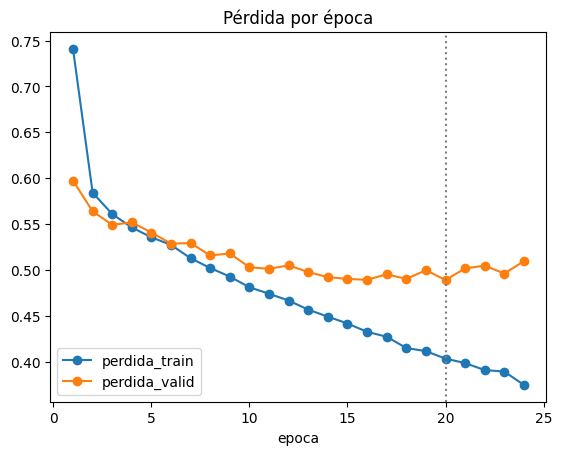

              precision    recall  f1-score   support

    negativo     0.6409    0.6504    0.6456      1476
     neutral     0.9638    0.9741    0.9689      1120
    positivo     0.6507    0.6359    0.6432      1497

    accuracy                         0.7337      4093
   macro avg     0.7518    0.7535    0.7526      4093
weighted avg     0.7328    0.7337    0.7332      4093



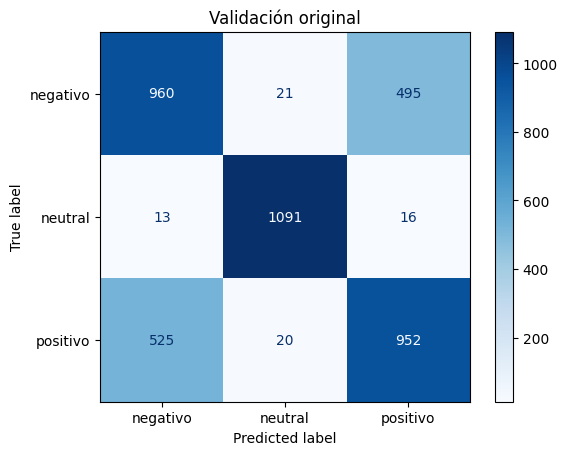

,ejemplos,accuracy,f1_macro
idioma,,,
en,470,0.8064,0.8084
es,2700,0.7159,0.7388
es_en_probable,22,0.6818,0.4505
fr,414,0.7367,0.7567
incierto,10,1.0000,1.0000
otra_mezcla_probable,15,0.8000,0.7802
pt,462,0.7554,0.7671


Brecha de entrenamiento y validación: 8.27 puntos porcentuales.
Errores de validación: 1090


,id,idioma_estimado,label,prediccion,confianza,text
0,2104,en,negativo,neutral,0.999761,"I bought this online and it arrived in about three days at my place. There were several units in the package, and I checked each one of them one by one. The assembly ended up b..."
1,13943,en,negativo,neutral,0.998440,"The package arrived midweek, I think it took about four days from when I placed the order. I ordered it online because I couldn't find it in the stores around my area, and it w..."
2,12116,en,negativo,neutral,0.997174,"I bought it in mid-September and it arrived in about five days. The unit works on 120 volts, so I plugged it directly into the living room outlet without any issues. The box ca..."
3,7001,fr,negativo,positivo,0.996809,"On l'a acheté en janvier pour remplacer notre vieux matelas de dix ans, celui qu'on avait acheté pour la chambre d'amis d'abord. Ma femme dort dessus tous les soirs et moi en w..."
4,2514,es,negativo,positivo,0.995859,"Lo pedí un martes por la tarde y me llegó al día siguiente, así que en envío no hubo problema. La usé desde el primer día en la oficina. El servicio se mantuvo aparatoso en mi ..."
5,6648,fr,negativo,neutral,0.995193,"J'ai acheté ce truc un mardi soir et il est arrivé au quatrième jour. Il y a une garantie d'un an, c'est écrit sur la boîte et sur le petit papier à l'intérieur. Je l'ai utilis..."
6,18040,es,neutral,positivo,0.992306,"Llegó el paquete hace unos días por la mensajería de siempre, sin demoras. Venían varias unidades adentro, revisé que estuvieran completas y todo bien. Desde entonces lo estoy ..."
7,16997,es,negativo,positivo,0.990864,"Lo compré a inicios de año y ya llevo varios meses usándolo bastante, lo tengo en la oficina. La tapa me salió estupenda hasta el momento. Eso sí, el manual de uso luce ordinar..."


In [49]:
mostrar_resultado(resultado_01)


### Submission del modelo 1

**Archivo subido a Kaggle:** `submission_v1_01.csv` — score público **0.71611**.

**Nombre descriptivo:** `submission_01_minilm_mlp_sin_aumento_colab.csv`. Mantiene el formato de los envíos anteriores e identifica la corrida en Colab. Conservamos ambos nombres con las mismas predicciones; no se vuelve a entrenar para crear esta copia.

In [50]:
# Submission del modelo 1
submission_01=preparar_envio(1)
registrar_score_publico(1)


Modelo 1: se conserva el modelo y el CSV ya verificados.
/content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab/submissions/submission_01_minilm_mlp_sin_aumento_colab.csv
Score público registrado: 0.71611 | Archivo subido: submission_v1_01.csv


### Resultado y comparación

| Accuracy de validación | F1 macro | Época elegida | Score público |
|---:|---:|---:|---:|
| 73.37 % | 0.7526 | 20 | 0.71611 |

Este es el punto de referencia: 73,37 % en validación y 0.71611 en Kaggle. La corrida local había obtenido 0.70923. La mejora observada no demuestra que la GPU sea su causa.

## Modelo 2: Fine-tuning de MiniLM sin aumento

### Planteamiento

El modelo 1 aprende solo el clasificador. Ahora ajustamos también MiniLM para adaptar las representaciones al sentimiento de las reseñas. Buscamos mejorar la clasificación de opiniones mezcladas.

### Arquitectura y configuración

MiniLM ajustable → promedio de tokens → dropout de 0,20 → capa lineal con tres salidas. El encoder usa una tasa de aprendizaje menor que el clasificador.

Estos parámetros pertenecen a este experimento.

In [51]:
NOMBRES_SUBMISSION[2]='submission_02_minilm_finetuning_sin_aumento_colab.csv'
BASES[2]=dict(MINILM)
CONFIGURACIONES[2]=dict(
    lr_encoder=3e-05,
    lr_head=0.0001,
    layer_decay=1.0,
    dropout=0.2,
    weight_decay=0.01,
    warmup_ratio=0.1,
    max_grad_norm=1.0,
    batch_size=16,
    grad_accum=2,
    eval_batch_size=64,
    max_epochs=6,
    patience=2,
    min_delta=0.0005
)
display(pd.Series(CONFIGURACIONES[2],name='Hiperparámetros del modelo 2'))


,Hiperparámetros del modelo 2
lr_encoder,0.00003
lr_head,0.00010
layer_decay,1.00000
dropout,0.20000
weight_decay,0.01000
warmup_ratio,0.10000
max_grad_norm,1.00000
batch_size,16.00000
grad_accum,2.00000
eval_batch_size,64.00000


### Entrenamiento

Recuperamos el resultado guardado de esta versión. Si falta y el entrenamiento está habilitado, ajustamos este modelo y elegimos la época con menor pérdida de validación.

In [52]:
resultado_02=desarrollar(2)


Resultados de desarrollo recuperados. Para otro intento, cambiar VERSION_CORRIDA.


### Evaluación

Revisamos las métricas, las curvas de pérdida, la matriz de confusión y los errores por idioma sobre la misma validación.

,Validación
accuracy,0.883704
f1_macro,0.892275
accuracy_train,0.919013
perdida_valid,0.232391


,epoca,perdida_train,ejemplos,ejemplos_aumentados,pasos_programados,actualizaciones,horizonte_epocas,perdida_valid,accuracy_valid,f1_macro_valid,segundos
0,1,0.527981,16373,0,512,508,6,0.273013,0.858783,0.868916,77.9
1,2,0.232656,16373,0,512,511,6,0.232391,0.883704,0.892275,78.3
2,3,0.169670,16373,0,512,512,6,0.244080,0.885658,0.894219,78.1
3,4,0.123486,16373,0,512,510,6,0.299710,0.881505,0.890777,78.4


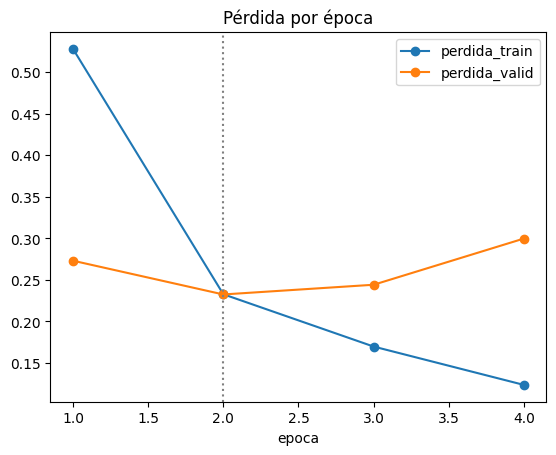

              precision    recall  f1-score   support

    negativo     0.7946    0.9201    0.8527      1476
     neutral     0.9946    0.9955    0.9951      1120
    positivo     0.9058    0.7642    0.8290      1497

    accuracy                         0.8837      4093
   macro avg     0.8983    0.8933    0.8923      4093
weighted avg     0.8900    0.8837    0.8830      4093



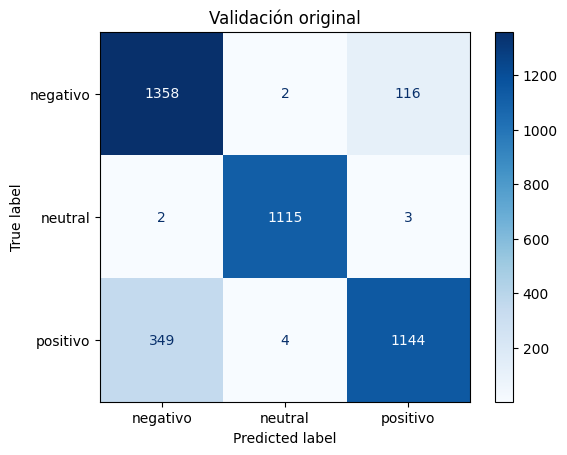

,ejemplos,accuracy,f1_macro
idioma,,,
en,470,0.8617,0.8635
es,2700,0.9015,0.9100
es_en_probable,22,0.7727,0.5123
fr,414,0.8140,0.8280
incierto,10,1.0000,1.0000
otra_mezcla_probable,15,0.8667,0.8667
pt,462,0.8680,0.8736


Brecha de entrenamiento y validación: 3.53 puntos porcentuales.
Errores de validación: 476


,id,idioma_estimado,label,prediccion,confianza,text
0,9673,en,positivo,negativo,0.994965,"I ordered it on a Tuesday and the usual courier delivered it, no hitches. I've been using it at the office pretty much every day for a month now. The battery life turned out a ..."
1,8374,fr,positivo,neutral,0.994481,"Je l'ai acheté il y a une paire de semaines pour l'utiliser au boulot, rien de plus. La livraison a pris moins de trois jours, c'est arrivé directement au bureau. Une chose que..."
2,3694,es,positivo,negativo,0.994315,"Me llegó el reproductor un martes por la tarde, dos días después de pedirlo, y venía bien empacado con su cable y su funda. Le compré una tarjeta de 128 GB aparte porque la que..."
3,18934,fr,negativo,positivo,0.994031,"Je l'ai acheté il y a quelques mois en promo, il est arrivé chez moi en quatre jours environ. Honnêtement, le poids s'est fait sentir avec le temps, ça se remarque quand on le ..."
4,6366,pt,positivo,negativo,0.990099,"Comprei esse kit no começo do ano e tenho ele no escritório desde então, uso todo dia no horário de trabalho. A correia funciona que é uma maravilha, uso todos os dias na camin..."
5,2070,es,negativo,positivo,0.989216,"Me llegó el paquete el jueves a la casa de mi hermana, donde estaba de visita esa semana. Para no hacer el cuento largo, pesa cerca de un kilo. Por cierto, el envío me resultó ..."
6,10805,es,positivo,neutral,0.988503,"Lo compré el mes pasado porque necesitaba uno chiquito para el cuarto. Me llegó en tres días más o menos, sin contratiempos. Hace poco lo estoy probando a fondo con las cosas d..."
7,12536,pt,negativo,positivo,0.987848,"Pedi na metade do mês e chegou em quatro dias numa caixa lacrada. É um modelo compacto que cabe de boa na gaveta da escrivaninha, eu deixo ele conectado no computador do quarto..."


In [53]:
mostrar_resultado(resultado_02)


### Submission del modelo 2

**Archivo subido a Kaggle:** `submission_v1_02.csv` — score público **0.86149**.

**Nombre descriptivo:** `submission_02_minilm_finetuning_sin_aumento_colab.csv`. Mantiene el formato de los envíos anteriores e identifica la corrida en Colab. Conservamos ambos nombres con las mismas predicciones; no se vuelve a entrenar para crear esta copia.

In [54]:
# Submission del modelo 2
submission_02=preparar_envio(2)
registrar_score_publico(2)


Modelo 2: se conserva el modelo y el CSV ya verificados.
/content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab/submissions/submission_02_minilm_finetuning_sin_aumento_colab.csv
Score público registrado: 0.86149 | Archivo subido: submission_v1_02.csv


### Resultado y comparación

| Accuracy de validación | F1 macro | Época elegida | Score público |
|---:|---:|---:|---:|
| 88.37 % | 0.8923 | 2 | 0.86149 |

Frente al modelo 1, mejora 15,00 puntos porcentuales en validación y 14,54 en el score público. El fine-tuning aporta una mejora clara en ambas evaluaciones. Frente al envío local equivalente, pasa de 0.85707 a 0.86149.

## Modelo 3: MiniLM con aumento de datos

### Planteamiento

Probamos si pequeñas variaciones del texto ayudan a generalizar. Conservamos la arquitectura, los hiperparámetros, la semilla y la validación del modelo 2; añadimos sustituciones léxicas durante el entrenamiento.

### Aumento de datos

En el tercer modelo cambiamos como máximo una expresión por reseña elegible, con probabilidad 0,30 por época. Las reglas cubren cuatro idiomas y conservan negaciones, conectores y números.

Las variantes se construyen solo con la parte que puede entrenarse. Rechazamos cambios invisibles para el tokenizador y colisiones conocidas con otra etiqueta. Son equivalencias aproximadas: revisamos ejemplos y medimos su efecto frente al modelo sin aumento.

In [55]:
import re
REGLAS_AUMENTO_03 = {
    'es': {
        'compré': 'adquirí', 'compre': 'adquiri', 'comprado': 'adquirido',
        'comprada': 'adquirida', 'utilizo': 'uso', 'utilizar': 'usar',
        'utilizarlo': 'usarlo', 'utilizarla': 'usarla', 'por internet': 'en línea',
        'en internet': 'en línea', 'todos los días': 'a diario',
        'todos los dias': 'a diario', 'principalmente': 'sobre todo',
        'habitualmente': 'normalmente', 'necesitaba': 'requería',
        'aparato': 'dispositivo',
    },
    'en': {
        'bought': 'purchased', 'purchased': 'bought', 'every day': 'daily',
        'each day': 'daily', 'primarily': 'mainly', 'approximately': 'roughly',
        'using': 'utilizing', 'manufacturer': 'maker',
        'initially': 'at first', 'afterwards': 'afterward',
        'at the moment': 'currently',
    },
    'pt': {
        'comprei': 'adquiri', 'comprado': 'adquirido', 'comprada': 'adquirida',
        'pela internet': 'online', 'todos os dias': 'diariamente',
        'eu uso': 'eu utilizo', 'usar': 'utilizar', 'usando': 'utilizando',
        'precisava': 'necessitava', 'no começo': 'no início',
    },
    'fr': {
        'acheté': 'acquis', 'achetée': 'acquise', 'acheter': 'acquérir',
        'chaque jour': 'quotidiennement', 'tous les jours': 'chaque jour',
        'principalement': 'essentiellement', 'utilisé': 'employé',
        'utilise': 'emploie', 'appareil': 'dispositif',
        'en ligne': 'sur internet',
    },
}
PROB_AUMENTO_03 = 0.30
patrones_aumento_03 = {
    idioma: [(re.compile(r'(?<!\w)' + re.escape(origen) + r'(?!\w)', re.I), origen, destino)
             for origen, destino in reglas.items()]
    for idioma, reglas in REGLAS_AUMENTO_03.items()
}
patron_protegido_03 = re.compile(
    r"(?<!\w)(?:no|not|never|without|neither|nor|n't|não|nunca|nem|sem|pas|jamais|"
    r"aucun|sans|rien|ni|nada|sin|pero|aunque|but|although|however|mas|porém|"
    r"embora|mais|pourtant|cependant)(?!\w)|n['’]|\d+(?:[.,]\d+)?", re.I)

def firma_protegida_03(texto):
    return tuple(m.group().casefold() for m in patron_protegido_03.finditer(texto))

def variante_03(texto, idioma, identificador, semilla=42):
    candidatos = []
    for patron, origen, destino in patrones_aumento_03.get(idioma, []):
        for coincidencia in patron.finditer(texto):
            candidatos.append((coincidencia.start(), coincidencia.end(), origen, destino))
    if not candidatos:
        return texto, 'sin_regla'
    valor = hashlib.sha256(f'{semilla}|{int(identificador)}|sinonimos_v1'.encode()).digest()
    inicio, fin, origen, destino = candidatos[int.from_bytes(valor[:8], 'big') % len(candidatos)]
    fragmento = texto[inicio:fin]
    if fragmento.isupper():
        destino = destino.upper()
    elif fragmento[0].isupper():
        destino = destino[0].upper() + destino[1:]
    nuevo = texto[:inicio] + destino + texto[fin:]
    assert firma_protegida_03(texto) == firma_protegida_03(nuevo)
    return nuevo, f'{idioma}: {origen} -> {destino}'

def preparar_aumentos_03(filas, idiomas, tokenizador, max_tokens=256, semilla=42):
    # Solo recibe la parte autorizada para entrenar; no consulta validación ni eval.
    if len(filas) != len(idiomas):
        raise ValueError('Debe haber un idioma por reseña')
    originales = filas['text'].tolist()
    variantes, reglas = [], []
    for fila, idioma in zip(filas.itertuples(), idiomas):
        texto, regla = variante_03(fila.text, idioma, fila.id, semilla)
        variantes.append(texto)
        reglas.append(regla)
    ids_originales = tokenizador(originales, truncation=True, max_length=max_tokens,
                                padding=False)['input_ids']
    ids_variantes = tokenizador(variantes, truncation=True, max_length=max_tokens,
                               padding=False)['input_ids']
    etiquetas_por_texto = {}
    for texto, etiqueta in zip(originales, filas['label']):
        etiquetas_por_texto.setdefault(texto.casefold().strip(), set()).add(etiqueta)
    motivos = []
    for i, (texto, etiqueta) in enumerate(zip(variantes, filas['label'])):
        motivo = 'aceptada'
        if reglas[i] == 'sin_regla':
            motivo = 'sin_regla'
        elif ids_variantes[i] == ids_originales[i]:
            motivo = 'sin_cambio_tokens'
        elif etiquetas_por_texto.get(texto.casefold().strip(), set()) - {etiqueta}:
            motivo = 'colision_con_otra_etiqueta'
        if motivo != 'aceptada':
            variantes[i] = originales[i]
            ids_variantes[i] = ids_originales[i]
        motivos.append(motivo)
    auditoria = filas[['id', 'label']].reset_index(drop=True).copy()
    auditoria['idioma_dominante'] = list(idiomas)
    auditoria['original'] = originales
    auditoria['variante'] = variantes
    auditoria['regla'] = reglas
    auditoria['control'] = motivos
    auditoria['aceptada'] = auditoria['control'].eq('aceptada')
    assert all(firma_protegida_03(a) == firma_protegida_03(b)
               for a, b in zip(originales, variantes))
    return ids_originales, ids_variantes, auditoria

### Arquitectura y configuración

Usamos la misma red del modelo 2. Las variantes se generan solo para entrenamiento, conservando negaciones, conectores y números.

Estos parámetros pertenecen a este experimento.

In [56]:
NOMBRES_SUBMISSION[3]='submission_03_minilm_finetuning_con_aumento_colab.csv'
BASES[3]=dict(MINILM)
CONFIGURACIONES[3]=dict(
    lr_encoder=3e-05,
    lr_head=0.0001,
    layer_decay=1.0,
    dropout=0.2,
    weight_decay=0.01,
    warmup_ratio=0.1,
    max_grad_norm=1.0,
    batch_size=16,
    grad_accum=2,
    eval_batch_size=64,
    max_epochs=6,
    patience=2,
    min_delta=0.0005
)
display(pd.Series(CONFIGURACIONES[3],name='Hiperparámetros del modelo 3'))


,Hiperparámetros del modelo 3
lr_encoder,0.00003
lr_head,0.00010
layer_decay,1.00000
dropout,0.20000
weight_decay,0.01000
warmup_ratio,0.10000
max_grad_norm,1.00000
batch_size,16.00000
grad_accum,2.00000
eval_batch_size,64.00000


### Entrenamiento

Recuperamos el resultado guardado de esta versión. Si falta y el entrenamiento está habilitado, ajustamos este modelo y elegimos la época con menor pérdida de validación.

In [57]:
resultado_03=desarrollar(3)


Resultados de desarrollo recuperados. Para otro intento, cambiar VERSION_CORRIDA.


### Evaluación

Revisamos las métricas, las curvas de pérdida, la matriz de confusión y los errores por idioma sobre la misma validación.

,Validación
accuracy,0.883948
f1_macro,0.893212
accuracy_train,0.931045
perdida_valid,0.229889


,epoca,perdida_train,ejemplos,ejemplos_aumentados,pasos_programados,actualizaciones,horizonte_epocas,perdida_valid,accuracy_valid,f1_macro_valid,segundos
0,1,0.531285,16373,3633,512,507,6,0.274494,0.860249,0.870195,77.7
1,2,0.232879,16373,3672,512,511,6,0.229889,0.883948,0.893212,79.0
2,3,0.167755,16373,3460,512,512,6,0.280546,0.880528,0.889798,79.2
3,4,0.124780,16373,3507,512,512,6,0.268473,0.887369,0.896322,79.0


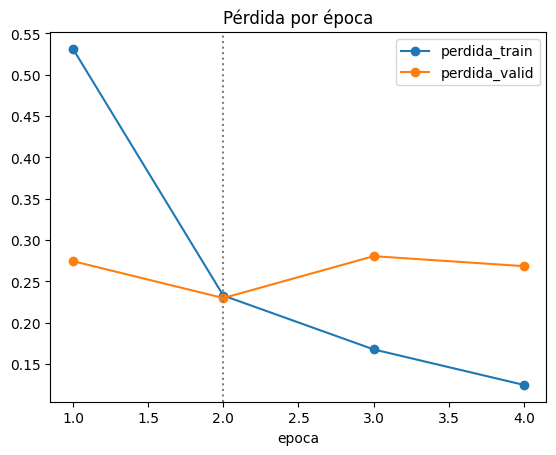

              precision    recall  f1-score   support

    negativo     0.8278    0.8631    0.8451      1476
     neutral     0.9982    0.9938    0.9960      1120
    positivo     0.8555    0.8223    0.8386      1497

    accuracy                         0.8839      4093
   macro avg     0.8938    0.8931    0.8932      4093
weighted avg     0.8845    0.8839    0.8840      4093



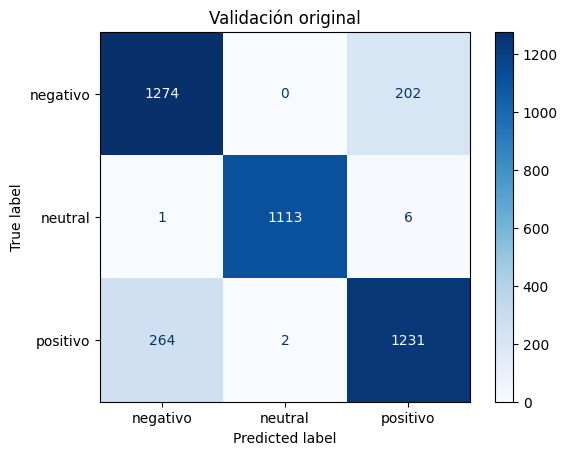

,ejemplos,accuracy,f1_macro
idioma,,,
en,470,0.8660,0.8685
es,2700,0.9048,0.9135
es_en_probable,22,0.7727,0.5148
fr,414,0.7947,0.8107
incierto,10,1.0000,1.0000
otra_mezcla_probable,15,0.8667,0.8667
pt,462,0.8636,0.8708


Brecha de entrenamiento y validación: 4.71 puntos porcentuales.
Errores de validación: 475


,id,idioma_estimado,label,prediccion,confianza,text
0,9673,en,positivo,negativo,0.995359,"I ordered it on a Tuesday and the usual courier delivered it, no hitches. I've been using it at the office pretty much every day for a month now. The battery life turned out a ..."
1,18934,fr,negativo,positivo,0.994347,"Je l'ai acheté il y a quelques mois en promo, il est arrivé chez moi en quatre jours environ. Honnêtement, le poids s'est fait sentir avec le temps, ça se remarque quand on le ..."
2,3694,es,positivo,negativo,0.994268,"Me llegó el reproductor un martes por la tarde, dos días después de pedirlo, y venía bien empacado con su cable y su funda. Le compré una tarjeta de 128 GB aparte porque la que..."
3,2692,es,negativo,positivo,0.993130,Lo compramos en enero para el cuarto de los kids y de verdad que es super comfortable. Yo que me levanto cada dos horas a acomodar el hundimiento del medio ahora sleep like a b...
4,5585,fr,positivo,negativo,0.992229,"Je l'ai commandé en promo et il est arrivé en quatre jours environ à la maison. Il y avait trois unités dans le paquet, donc ça a suffi pour en offrir une à ma sœur. Je l'ai mo..."
5,9135,pt,positivo,negativo,0.991239,"Comprei essa liquidificadora mês passado pra fazer as vitaminas do café da manhã, já que meu filho vive pedindo. A lâmina tritura até gelo sem esforço, o copo é grande e o moto..."
6,5439,fr,negativo,positivo,0.991153,"Ça fait plusieurs mois que j'ai cet appareil, je l'ai acheté pour le laisser au bureau où je m'en sers tous les jours entre les réunions. Il pèse environ 300 grammes, donc il n..."
7,6169,fr,negativo,positivo,0.990286,"J'ai acheté cet écran le mois dernier pour le télétravail, ma femme et moi on l'utilise tous les jours. Honnêtement, mon ancien modèle rendait mieux : les couleurs y étaient pl..."


In [58]:
mostrar_resultado(resultado_03)


### Submission del modelo 3

**Archivo subido a Kaggle:** `submission_v1_03.csv` — score público **0.85265**.

**Nombre descriptivo:** `submission_03_minilm_finetuning_con_aumento_colab.csv`. Mantiene el formato de los envíos anteriores e identifica la corrida en Colab. Conservamos ambos nombres con las mismas predicciones; no se vuelve a entrenar para crear esta copia.

In [59]:
# Submission del modelo 3
submission_03=preparar_envio(3)
registrar_score_publico(3)


Modelo 3: se conserva el modelo y el CSV ya verificados.
/content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab/submissions/submission_03_minilm_finetuning_con_aumento_colab.csv
Score público registrado: 0.85265 | Archivo subido: submission_v1_03.csv


### Resultado y comparación

| Accuracy de validación | F1 macro | Época elegida | Score público |
|---:|---:|---:|---:|
| 88.39 % | 0.8932 | 2 | 0.85265 |

El aumento mejoró una reseña de 4.093 en validación, pero su score público bajó de 0.86149 a 0.85265 respecto al modelo 2. En esta corrida no fue una mejora para la competencia. Tampoco supera el envío local con aumento, que obtuvo 0.85903.

## Modelo 4: XLM-RoBERTa con ajuste por capas

### Planteamiento

Después de comparar el aumento, probamos un encoder multilingüe de mayor capacidad. Buscamos mejorar el resultado con XLM-RoBERTa, manteniendo la misma validación para comparar.

### Arquitectura y configuración

XLM-R base → primer token → capa densa con tanh → dropout → tres salidas. Los embeddings quedan fijos y las capas inferiores reciben tasas de aprendizaje menores.

Estos parámetros pertenecen a este experimento.

In [60]:
NOMBRES_SUBMISSION[4]='submission_04_xlmr_finetuning_por_capas_colab.csv'
BASES[4]=dict(XLMR)
CONFIGURACIONES[4]=dict(
    lr_encoder=2e-05,
    lr_head=0.0001,
    layer_decay=0.9,
    dropout=0.2,
    weight_decay=0.01,
    warmup_ratio=0.1,
    max_grad_norm=1.0,
    batch_size=8,
    grad_accum=4,
    eval_batch_size=32,
    max_epochs=4,
    patience=2,
    min_delta=0.0005
)
display(pd.Series(CONFIGURACIONES[4],name='Hiperparámetros del modelo 4'))


,Hiperparámetros del modelo 4
lr_encoder,0.00002
lr_head,0.00010
layer_decay,0.90000
dropout,0.20000
weight_decay,0.01000
warmup_ratio,0.10000
max_grad_norm,1.00000
batch_size,8.00000
grad_accum,4.00000
eval_batch_size,32.00000


### Entrenamiento

Recuperamos el resultado guardado de esta versión. Si falta y el entrenamiento está habilitado, ajustamos este modelo y elegimos la época con menor pérdida de validación.

In [61]:
resultado_04=desarrollar(4)


Resultados de desarrollo recuperados. Para otro intento, cambiar VERSION_CORRIDA.


### Evaluación

Revisamos las métricas, las curvas de pérdida, la matriz de confusión y los errores por idioma sobre la misma validación.

,Validación
accuracy,0.897874
f1_macro,0.905727
accuracy_train,0.917364
perdida_valid,0.198373


,epoca,perdida_train,ejemplos,ejemplos_aumentados,pasos_programados,actualizaciones,horizonte_epocas,perdida_valid,accuracy_valid,f1_macro_valid,segundos
0,1,0.517459,16373,0,512,504,4,0.201132,0.891522,0.900288,109.4
1,2,0.210103,16373,0,512,512,4,0.198373,0.897874,0.905727,111.0
2,3,0.160303,16373,0,512,511,4,0.206421,0.901295,0.909236,111.1
3,4,0.135195,16373,0,512,512,4,0.204674,0.899096,0.907039,111.7


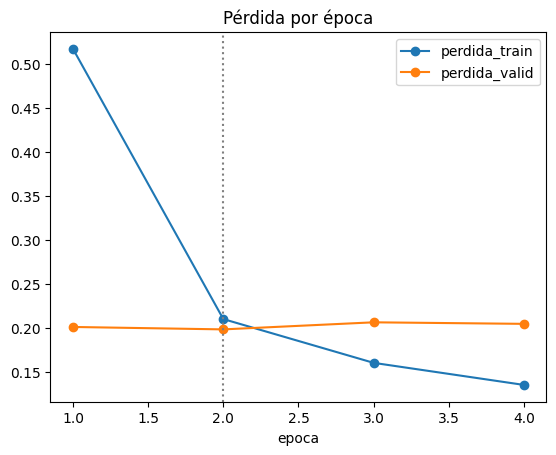

              precision    recall  f1-score   support

    negativo     0.8166    0.9289    0.8691      1476
     neutral     0.9991    0.9946    0.9969      1120
    positivo     0.9161    0.7949    0.8512      1497

    accuracy                         0.8979      4093
   macro avg     0.9106    0.9061    0.9057      4093
weighted avg     0.9029    0.8979    0.8975      4093



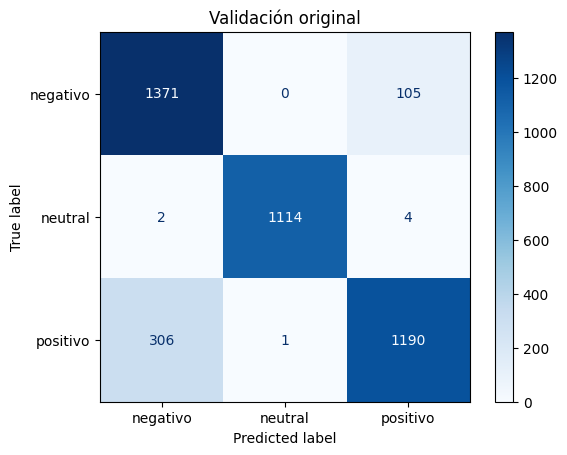

,ejemplos,accuracy,f1_macro
idioma,,,
en,470,0.8957,0.8978
es,2700,0.9119,0.9196
es_en_probable,22,0.7273,0.4786
fr,414,0.8406,0.8533
incierto,10,1.0000,1.0000
otra_mezcla_probable,15,0.8000,0.8054
pt,462,0.8788,0.8849


Brecha de entrenamiento y validación: 1.95 puntos porcentuales.
Errores de validación: 418


,id,idioma_estimado,label,prediccion,confianza,text
0,9673,en,positivo,negativo,0.999558,"I ordered it on a Tuesday and the usual courier delivered it, no hitches. I've been using it at the office pretty much every day for a month now. The battery life turned out a ..."
1,7001,fr,negativo,positivo,0.999525,"On l'a acheté en janvier pour remplacer notre vieux matelas de dix ans, celui qu'on avait acheté pour la chambre d'amis d'abord. Ma femme dort dessus tous les soirs et moi en w..."
2,14547,pt,negativo,positivo,0.999340,"Comprei esses fones sem fio mês passado pra academia e a bateria ""dura o dia inteiro"", desde que o dia tenha uns quarenta minutos: treino de manhã e às onze já tá apitando que ..."
3,18934,fr,negativo,positivo,0.999337,"Je l'ai acheté il y a quelques mois en promo, il est arrivé chez moi en quatre jours environ. Honnêtement, le poids s'est fait sentir avec le temps, ça se remarque quand on le ..."
4,12536,pt,negativo,positivo,0.998903,"Pedi na metade do mês e chegou em quatro dias numa caixa lacrada. É um modelo compacto que cabe de boa na gaveta da escrivaninha, eu deixo ele conectado no computador do quarto..."
5,13963,fr,negativo,positivo,0.998779,"On me l'a offerte pour mon anniversaire en mars, et honnêtement c'est du rapide, le café est prêt en deux minutes (quand il daigne démarrer, c'est déjà ça). Le matin, toute la ..."
6,19004,fr,negativo,positivo,0.998694,"Je l'ai acheté il y a quelques jours et je l'ai installé au bureau, sur le bureau à côté de la fenêtre. Chaque centime payé pour le menu de réglages en valait la peine. Le sign..."
7,556,fr,negativo,positivo,0.998550,"Je l'ai commandé à la mi-octobre et il m'est arrivé au boulot en environ quatre jours, dans une boîte scellée et tout. Je l'ai branché le week-end même pour l'essayer avec la t..."


In [62]:
mostrar_resultado(resultado_04)


### Submission del modelo 4

**Archivo subido a Kaggle:** `submission_v1_04.csv` — score público **0.87524**.

**Nombre descriptivo:** `submission_04_xlmr_finetuning_por_capas_colab.csv`. Mantiene el formato de los envíos anteriores e identifica la corrida en Colab. Conservamos ambos nombres con las mismas predicciones; no se vuelve a entrenar para crear esta copia.

In [63]:
# Submission del modelo 4
submission_04=preparar_envio(4)
registrar_score_publico(4)


Modelo 4: se conserva el modelo y el CSV ya verificados.
/content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab/submissions/submission_04_xlmr_finetuning_por_capas_colab.csv
Score público registrado: 0.87524 | Archivo subido: submission_v1_04.csv


### Resultado y comparación

| Accuracy de validación | F1 macro | Época elegida | Score público |
|---:|---:|---:|---:|
| 89.79 % | 0.9057 | 2 | 0.87524 |

Al completar este intento era el mejor modelo en las dos evaluaciones: 89,79 % en validación y 0.87524 en Kaggle. Supera al mejor envío anterior, el modelo 2, en 1,375 puntos porcentuales de score público. Será nuestra base para el siguiente experimento.

## Modelo 5: Ensamble de XLM-R y MiniLM

### Planteamiento

XLM-R obtuvo el mejor score público (0.87524). Combinamos sus probabilidades con MiniLM sin aumento para aprovechar errores diferentes. Usamos 90 % de XLM-R y 10 % de MiniLM; no mezclamos las etiquetas finales.

El peso se eligió entre seis opciones en la misma validación de desarrollo. La mejora es orientativa: no es una prueba independiente ni garantiza mejorar en Kaggle. No usamos etiquetas de eval.

### Configuración

Conservamos las redes ya entrenadas, los textos con tildes, el límite de 256 tokens y el orden negativo, neutral, positivo. El paquete final incluye ambas redes y sus tokenizadores.


In [64]:
import zipfile

CONFIGURACION_05=dict(tipo='promedio_probabilidades',miembros=[4,2],pesos=[0.9,0.1],
    etiquetas=list(ETIQUETAS),max_tokens=MAX_TOKENS,version=VERSION_CORRIDA,
    seleccion_pesos='Validación de desarrollo; seis pesos candidatos, sin etiquetas de eval')
RUTAS_05=dict(modelo=CARPETA_PROYECTO/f'modelo_{VERSION_CORRIDA}_05.zip',
    resultado=CARPETA_PROYECTO/f'resultados_{VERSION_CORRIDA}_05.json',
    estado=CARPETA_PROYECTO/f'estado_{VERSION_CORRIDA}_05.json',
    submission=CARPETA_PROYECTO/'submissions'/'submission_05_ensemble_xlmr_minilm_colab.csv')
display(pd.Series(CONFIGURACION_05,name='Configuración del modelo 5'))


,Configuración del modelo 5
tipo,promedio_probabilidades
miembros,"[4, 2]"
pesos,"[0.9, 0.1]"
etiquetas,"[negativo, neutral, positivo]"
max_tokens,256
version,v1
seleccion_pesos,Validación de desarrollo; seis pesos candidato...


### Entrenamiento y selección

No ajustamos otra red. Los miembros finales ya aprendieron con todo train después de elegir su época en desarrollo. Solo elegimos cómo promediar sus probabilidades, usando las predicciones de validación que se guardaron antes del ajuste final.


In [65]:
registros_05={2:leer_resultado(2),4:leer_resultado(4)}
p_minilm_05=pd.DataFrame(registros_05[2]['predicciones_validacion'])
p_xlmr_05=pd.DataFrame(registros_05[4]['predicciones_validacion'])
assert p_minilm_05['id'].tolist()==p_xlmr_05['id'].tolist()
assert p_minilm_05['label'].tolist()==p_xlmr_05['label'].tolist()
columnas_05=['p_'+c for c in ETIQUETAS]
prueba_mezclas_05=[]
for peso_xlmr_05 in [1.0,0.9,0.8,0.7,0.6,0.5]:
    probabilidades_05=(peso_xlmr_05*p_xlmr_05[columnas_05].to_numpy()
        +(1-peso_xlmr_05)*p_minilm_05[columnas_05].to_numpy())
    predicciones_05=np.array(ETIQUETAS)[probabilidades_05.argmax(1)]
    prueba_mezclas_05.append(dict(peso_xlmr=peso_xlmr_05,peso_minilm=round(1-peso_xlmr_05,2),
        accuracy=accuracy_score(p_xlmr_05['label'],predicciones_05),
        f1_macro=f1_score(p_xlmr_05['label'],predicciones_05,labels=ETIQUETAS,average='macro'),
        aciertos=int((predicciones_05==p_xlmr_05['label'].to_numpy()).sum())))
display(pd.DataFrame(prueba_mezclas_05).round(4))


,peso_xlmr,peso_minilm,accuracy,f1_macro,aciertos
0,1.0,0.0,0.8979,0.9057,3675
1,0.9,0.1,0.9008,0.9084,3687
2,0.8,0.2,0.8996,0.9072,3682
3,0.7,0.3,0.8984,0.9061,3677
4,0.6,0.4,0.8993,0.9070,3681
5,0.5,0.5,0.8998,0.9074,3683


In [66]:
# Evaluación con miembros de desarrollo: nunca con las redes finales sobre validación.
probas_valid_05=(CONFIGURACION_05['pesos'][0]*p_xlmr_05[columnas_05].to_numpy()
    +CONFIGURACION_05['pesos'][1]*p_minilm_05[columnas_05].to_numpy())
validacion_05=p_xlmr_05[['id','label','idioma_estimado']].copy()
validacion_05['prediccion']=np.array(ETIQUETAS)[probas_valid_05.argmax(1)]
validacion_05['confianza']=probas_valid_05.max(1)
for i,c in enumerate(ETIQUETAS):
    validacion_05['p_'+c]=probas_valid_05[:,i]
metricas_05=dict(accuracy=float(accuracy_score(validacion_05['label'],validacion_05['prediccion'])),
    f1_macro=float(f1_score(validacion_05['label'],validacion_05['prediccion'],labels=ETIQUETAS,average='macro')))
resultado_05=dict(experimento=5,configuracion=CONFIGURACION_05,datos=HUELLAS_ESPERADAS,
    metricas=metricas_05,prueba_pesos=prueba_mezclas_05,
    predicciones_validacion=validacion_05.to_dict('records'),
    ids_desarrollo=train.iloc[INDICES_TRAIN]['id'].tolist(),score_publico=None)


### Evaluación

Revisamos accuracy, F1 macro, matriz de confusión y resultados por idioma. No hay nuevas épocas ni curva de entrenamiento del ensamble: se reutilizan los dos modelos anteriores.


,Validación del ensamble
accuracy,0.900806
f1_macro,0.908386


              precision    recall  f1-score   support

    negativo     0.8182    0.9363    0.8733      1476
     neutral     0.9991    0.9946    0.9969      1120
    positivo     0.9240    0.7956    0.8550      1497

    accuracy                         0.9008      4093
   macro avg     0.9138    0.9088    0.9084      4093
weighted avg     0.9064    0.9008    0.9004      4093



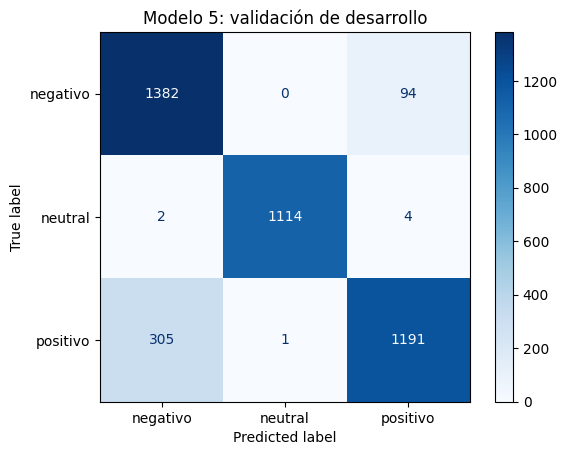

,ejemplos,accuracy,f1_macro
idioma,,,
en,470,0.9000,0.9019
es,2700,0.9144,0.9220
es_en_probable,22,0.7273,0.4786
fr,414,0.8430,0.8554
incierto,10,1.0000,1.0000
otra_mezcla_probable,15,0.8000,0.8054
pt,462,0.8831,0.8889


Aciertos adicionales frente a XLM-R: 12


In [67]:
display(pd.Series(metricas_05,name='Validación del ensamble'))
print(classification_report(validacion_05['label'],validacion_05['prediccion'],labels=ETIQUETAS,digits=4,zero_division=0))
ConfusionMatrixDisplay.from_predictions(validacion_05['label'],validacion_05['prediccion'],labels=ETIQUETAS,cmap='Blues')
plt.title('Modelo 5: validación de desarrollo')
plt.show()
display(pd.DataFrame([dict(idioma=idioma,ejemplos=len(filas),
    accuracy=accuracy_score(filas['label'],filas['prediccion']),
    f1_macro=f1_score(filas['label'],filas['prediccion'],labels=ETIQUETAS,average='macro',zero_division=0))
    for idioma,filas in validacion_05.groupby('idioma_estimado')]).set_index('idioma').round(4))
print('Aciertos adicionales frente a XLM-R:',int(validacion_05['label'].eq(validacion_05['prediccion']).sum()
    -p_xlmr_05['label'].eq(p_xlmr_05['prediccion']).sum()))


### Guardado e inferencia

Guardamos un ZIP con los dos modelos completos, sus tokenizadores, configuración, licencias y huellas. Luego lo abrimos de nuevo y comprobamos las probabilidades y las 6.781 predicciones. La función `predecir_ensamble_05` permite usar ese paquete en otra sesión con las funciones generales del cuaderno, sin descargar otra vez los pesos base.

Run all reutiliza el paquete y el CSV si sus huellas siguen coincidiendo. Esta sección no reentrena los modelos 2 y 4.


In [68]:
def huella_archivo_05(ruta):
    h=hashlib.sha256()
    with open(ruta,'rb') as archivo:
        for bloque in iter(lambda:archivo.read(8*1024*1024),b''):
            h.update(bloque)
    return h.hexdigest()


def estado_05(etapa,**datos):
    guardar_atomico(dict(etapa=etapa,**datos),RUTAS_05['estado'],formato='json')
    print('Modelo 5:',etapa,flush=True)


def probabilidades_miembro_05(ruta,numero,textos):
    tok,red,meta=cargar_modelo_completo(ruta,DISPOSITIVO)
    try:
        if meta['numero']!=numero:
            raise ValueError('El número del miembro no coincide.')
        ids=tok(list(textos),truncation=True,max_length=MAX_TOKENS,padding=False)['input_ids']
        p,_=predecir(red,DatosTexto(ids),numero,tok)
        if p.shape!=(len(textos),len(ETIQUETAS)) or (p<0).any() or not np.allclose(p.sum(1),1,atol=1e-5):
            raise ValueError('Probabilidades inválidas o con otro orden.')
        return p
    finally:
        del red,tok
        liberar_memoria()


def predecir_ensamble_05(ruta,textos):
    # Extraer solo los nombres explícitos del manifiesto, uno por vez.
    with zipfile.ZipFile(ruta) as paquete:
        manifiesto=json.loads(paquete.read('manifest.json'))
        if manifiesto['configuracion']!=CONFIGURACION_05 or manifiesto['datos']!=HUELLAS_ESPERADAS:
            raise ValueError('El paquete corresponde a otra configuración o datos.')
        acumuladas=None
        for miembro,peso in zip(manifiesto['miembros'],manifiesto['configuracion']['pesos']):
            numero=miembro['numero']
            if miembro['archivo']!=f'miembro_{numero:02d}.pt' or miembro['firma']!=firma_experimento(numero):
                raise ValueError('Revisar identidad y configuración del miembro.')
            estado_05(f'Recarga e inferencia del miembro {numero}')
            with tempfile.TemporaryDirectory(dir=CARPETA_LOCAL) as carpeta:
                local=Path(carpeta)/f'miembro_{numero:02d}.pt'
                with paquete.open(miembro['archivo']) as origen,local.open('wb') as destino:
                    shutil.copyfileobj(origen,destino,length=8*1024*1024)
                if huella_archivo_05(local)!=miembro['sha256']:
                    raise ValueError('El miembro no pasó la verificación de integridad.')
                p=probabilidades_miembro_05(local,numero,textos)
                acumuladas=p*peso if acumuladas is None else acumuladas+p*peso
    return acumuladas


def crear_submission_05():
    if not GENERAR_SUBMISSION:
        print('Generación del modelo 5 desactivada.')
        return None
    try:
        miembros=[]
        for numero in CONFIGURACION_05['miembros']:
            ruta=rutas_experimento(numero)['modelo']
            if not ruta.is_file():
                raise FileNotFoundError(f'Falta el modelo final {numero}; ejecutar su sección primero.')
            miembros.append(dict(numero=numero,archivo=f'miembro_{numero:02d}.pt',
                sha256=huella_archivo_05(ruta),firma=firma_experimento(numero)))
        firma=dict(configuracion=CONFIGURACION_05,datos=HUELLAS_ESPERADAS,miembros=miembros)
        if all(RUTAS_05[k].is_file() for k in ['resultado','modelo','submission']):
            previo=json.loads(RUTAS_05['resultado'].read_text())
            if (previo.get('firma')==firma and previo.get('verificacion_recarga_completa')
                    and previo.get('modelo_sha256')==huella_archivo_05(RUTAS_05['modelo'])
                    and previo.get('submission_sha256')==huella_archivo_05(RUTAS_05['submission'])):
                sub=pd.read_csv(RUTAS_05['submission'])
                verificar_submission(sub)
                resultado_05.update(previo)
                estado_05('Completado; paquete y CSV existentes verificados',filas=len(sub),
                    csv=str(RUTAS_05['submission']),sha256=previo['submission_sha256'])
                return sub
        manifiesto=dict(**firma,entorno=ENTORNO,licencias=LICENCIAS,
            descripcion='Ensamble de redes finales entrenadas con todo train; pesos elegidos en desarrollo.',
            resultado_desarrollo=resultado_05)
        # Inferencia original desde los dos paquetes guardados.
        antes=None
        textos=eval_df['text'].tolist()
        for miembro,peso in zip(miembros,CONFIGURACION_05['pesos']):
            numero=miembro['numero']
            estado_05(f'Inferencia original del miembro {numero}')
            p=probabilidades_miembro_05(rutas_experimento(numero)['modelo'],numero,textos)
            antes=p*peso if antes is None else antes+p*peso
        estado_05('Guardando paquete completo de los dos modelos')
        with tempfile.TemporaryDirectory(dir=CARPETA_LOCAL) as carpeta:
            local=Path(carpeta)/RUTAS_05['modelo'].name
            with zipfile.ZipFile(local,'w',compression=zipfile.ZIP_STORED,allowZip64=True) as paquete:
                paquete.writestr('manifest.json',json.dumps(manifiesto,ensure_ascii=False,indent=2))
                for miembro in miembros:
                    paquete.write(rutas_experimento(miembro['numero'])['modelo'],miembro['archivo'])
            parcial=RUTAS_05['modelo'].with_suffix('.zip.parcial')
            shutil.copyfile(local,parcial)
            os.replace(parcial,RUTAS_05['modelo'])
        despues=predecir_ensamble_05(RUTAS_05['modelo'],textos)
        if not np.allclose(antes,despues,atol=1e-5,rtol=1e-5) or not np.array_equal(antes.argmax(1),despues.argmax(1)):
            raise ValueError('La recarga no reproduce todas las predicciones.')
        sub=pd.DataFrame({'id':eval_df['id'],'answer':np.array(ETIQUETAS)[despues.argmax(1)]})
        verificar_submission(sub)
        contenido=sub.to_csv(index=False).encode()
        RUTAS_05['submission'].parent.mkdir(exist_ok=True)
        parcial=RUTAS_05['submission'].with_suffix('.csv.parcial')
        parcial.write_bytes(contenido)
        os.replace(parcial,RUTAS_05['submission'])
        resultado_05.update(firma=firma,entorno_final=ENTORNO,verificacion_recarga_completa=True,
            filas_verificadas=len(sub),diferencia_maxima_recarga=float(np.max(np.abs(antes-despues))),
            submission_sha256=hashlib.sha256(contenido).hexdigest(),modelo_sha256=huella_archivo_05(RUTAS_05['modelo']))
        guardar_atomico(resultado_05,RUTAS_05['resultado'],formato='json')
        estado_05('Completado',filas=len(sub),csv=str(RUTAS_05['submission']),
            sha256=resultado_05['submission_sha256'],recarga_verificada=True)
        print('Modelo completo:',RUTAS_05['modelo'])
        print('CSV listo:',RUTAS_05['submission'])
        return sub
    except Exception as error:
        estado_05('Error',detalle=str(error))
        raise


### Submission del modelo 5

Archivo: `submissions/submission_05_ensemble_xlmr_minilm_colab.csv`. Score público confirmado por el usuario: **0.87770**. Se registra solo si coincide la huella del CSV enviado.


In [69]:
submission_05=crear_submission_05()
if submission_05 is not None:
    display(submission_05.head())
    display(submission_05['answer'].value_counts().to_frame('Predicciones'))
if submission_05 is not None:
    evidencia_05=dict(score=0.87770,archivo_subido='submission_05_ensemble_xlmr_minilm_colab.csv',
        sha256='c292de9f52a58386746efc120622d1498da507245554b4828b1ee07d8ff865b2',
        fuente='Score público reportado por el usuario')
    if huella_archivo_05(RUTAS_05['submission'])==evidencia_05['sha256']:
        resultado_05.update(score_publico=evidencia_05['score'],registro_kaggle=evidencia_05)
        guardar_atomico(resultado_05,RUTAS_05['resultado'],formato='json')


Modelo 5: Completado; paquete y CSV existentes verificados


,id,answer
0,0,positivo
1,1,neutral
2,2,positivo
3,3,neutral
4,4,negativo


,Predicciones
answer,
positivo,3125
negativo,2358
neutral,1298


### Resultado y comparación

El ensamble obtuvo **90,08 %** de accuracy y **0,9084** de F1 macro en desarrollo: acertó 12 reseñas más que XLM-R solo. En Kaggle obtuvo **0.87770**, frente a 0.87524 del modelo 4: una mejora de 0,246 puntos porcentuales.

La validación sobreestima el resultado público en este intento. La mayoría de sus errores son positivos clasificados como negativos (305 casos); el francés alcanza 84,30 % en validación. Buscamos mejorar la representación del texto con un encoder de mayor capacidad.


## Modelo 6: XLM-RoBERTa large

### Planteamiento

El ensamble 5 alcanzó 0.87770 en Kaggle. En vez de seguir ajustando sus pesos sobre la misma validación, probamos un encoder de mayor capacidad. XLM-R large tiene 24 capas y vectores de 1.024 dimensiones, frente a 12 capas y 768 de la base anterior.

La hipótesis es que represente mejor negaciones, contrastes y reseñas multilingües. Es una hipótesis que evaluamos; no garantiza llegar a 0.90 en Kaggle. Conservamos los mismos datos y la misma partición. No usamos eval para aprender ni elegir parámetros.

### Arquitectura y configuración

[XLM-R large](https://huggingface.co/FacebookAI/xlm-roberta-large), licencia MIT → primer token → capa densa con tanh y dropout → tres clases. Dejamos los embeddings fijos y ajustamos las 24 capas, con una tasa menor en las inferiores.

Usamos precisión mixta, acumulación de gradientes y recomputación de activaciones para reducir la memoria de GPU. No cambiamos los resultados ni las configuraciones de los cinco intentos anteriores. Esta red se prueba sin aumento para distinguirla del experimento de sustituciones de los modelos 2 y 3.


In [70]:
BASES[6]=dict(nombre='FacebookAI/xlm-roberta-large',
    revision='c23d21b0620b635a76227c604d44e43a9f0ee389',licencia='MIT')
NOMBRES_SUBMISSION[6]='submission_06_xlmr_large_colab.csv'
CONFIGURACIONES[6]=dict(lr_encoder=1.5e-5,lr_head=5e-5,layer_decay=0.95,
    dropout=0.1,weight_decay=0.01,warmup_ratio=0.1,max_grad_norm=1.0,
    batch_size=16,grad_accum=2,eval_batch_size=16,max_epochs=4,patience=1,
    min_delta=0.0005,gradient_checkpointing=True)
RUTA_ESTADO_06=CARPETA_PROYECTO/f'estado_{VERSION_CORRIDA}_06.json'

def estado_06(estado,**informacion):
    guardar_atomico(dict(estado=estado,**informacion),RUTA_ESTADO_06,formato='json')

def ejecutar_desarrollo_06():
    try:
        estado_06('Preparando el modelo y los datos')
        resultado=desarrollar(6)
        if resultado is not None:
            estado_06('Desarrollo completado',metricas=resultado['metricas'],
                epoca_seleccionada=resultado['epoca_seleccionada'])
        return resultado
    except Exception as error:
        estado_06('Error en desarrollo',detalle=str(error))
        raise

def ejecutar_submission_06():
    try:
        estado_06('Preparando ajuste final e inferencia')
        sub=preparar_envio(6)
        if sub is not None:
            estado_06('Completado',filas=len(sub),csv=str(rutas_experimento(6)['submission']),
                sha256=hashlib.sha256(rutas_experimento(6)['submission'].read_bytes()).hexdigest())
        return sub
    except Exception as error:
        estado_06('Error en ajuste final o inferencia',detalle=str(error))
        raise

display(pd.Series(CONFIGURACIONES[6],name='Hiperparámetros del modelo 6'))


,Hiperparámetros del modelo 6
lr_encoder,0.000015
lr_head,0.00005
layer_decay,0.95
dropout,0.1
weight_decay,0.01
warmup_ratio,0.1
max_grad_norm,1.0
batch_size,16
grad_accum,2
eval_batch_size,16


### Entrenamiento

Empezamos desde los pesos públicos y ajustamos con las 16.373 reseñas de desarrollo. Elegimos la época de menor pérdida de validación, hasta cuatro épocas y con parada temprana. Dropout y weight decay ayudan a limitar el sobreajuste. Guardamos un checkpoint después de cada época; si la sesión se interrumpe, se recupera la última época completa.


In [71]:
resultado_06=ejecutar_desarrollo_06()


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Época 1: lote 1/1024
Época 1: lote 50/1024
Época 1: lote 100/1024
Época 1: lote 150/1024
Época 1: lote 200/1024
Época 1: lote 250/1024
Época 1: lote 300/1024
Época 1: lote 350/1024
Época 1: lote 400/1024
Época 1: lote 450/1024
Época 1: lote 500/1024
Época 1: lote 550/1024
Época 1: lote 600/1024
Época 1: lote 650/1024
Época 1: lote 700/1024
Época 1: lote 750/1024
Época 1: lote 800/1024
Época 1: lote 850/1024
Época 1: lote 900/1024
Época 1: lote 950/1024
Época 1: lote 1000/1024
Inferencia: lote 1/256
Inferencia: lote 100/256
Inferencia: lote 200/256
{'epoca': 1, 'perdida_train': 0.4822445873537181, 'ejemplos': 16373, 'ejemplos_aumentados': 0, 'pasos_programados': 512, 'actualizaciones': 503, 'horizonte_epocas': 4, 'perdida_valid': 0.18215751457907534, 'accuracy_valid': 0.8978744197410212, 'f1_macro_valid': 0.9058897217560625, 'segundos': 296.7}
Checkpoint guardado en Drive.
Época 2: lote 1/1024
Época 2: lote 50/1024
Época 2: lote 100/1024
Época 2: lote 150/1024
Época 2: lote 200/1024
Épo

### Evaluación

Mostramos curvas, accuracy, F1 macro, brecha con entrenamiento y errores por idioma. Las métricas corresponden al modelo de desarrollo, antes de aprender con todo train. Contrastamos el resultado con XLM-R base y el ensamble; una mejora en esta validación debe confirmarse en Kaggle.


,Validación
accuracy,0.897874
f1_macro,0.905890
accuracy_train,0.910951
perdida_valid,0.182158


,epoca,perdida_train,ejemplos,ejemplos_aumentados,pasos_programados,actualizaciones,horizonte_epocas,perdida_valid,accuracy_valid,f1_macro_valid,segundos
0,1,0.482245,16373,0,512,503,4,0.182158,0.897874,0.905890,296.7
1,2,0.199151,16373,0,512,510,4,0.186104,0.903005,0.909831,298.4


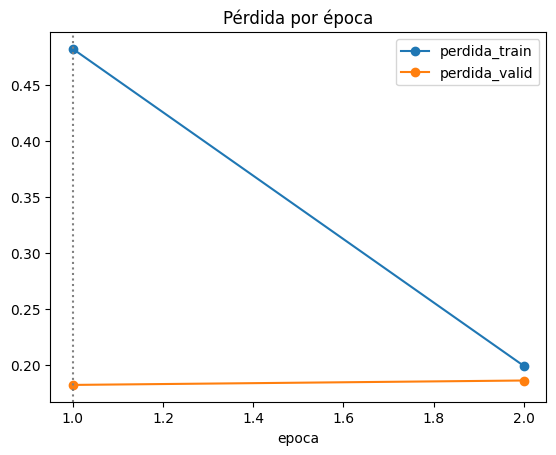

              precision    recall  f1-score   support

    negativo     0.8800    0.8347    0.8567      1476
     neutral     0.9964    0.9964    0.9964      1120
    positivo     0.8436    0.8864    0.8645      1497

    accuracy                         0.8979      4093
   macro avg     0.9067    0.9059    0.9059      4093
weighted avg     0.8986    0.8979    0.8978      4093



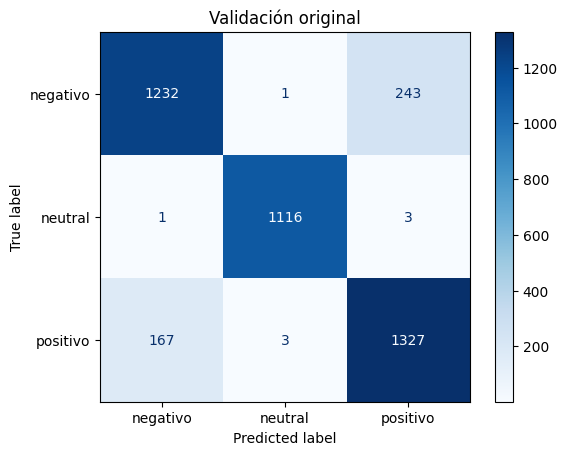

,ejemplos,accuracy,f1_macro
idioma,,,
en,470,0.8979,0.8990
es,2700,0.9126,0.9204
es_en_probable,22,0.7273,0.4833
fr,414,0.8285,0.8426
incierto,10,1.0000,1.0000
otra_mezcla_probable,15,0.8667,0.8611
pt,462,0.8810,0.8871


Brecha de entrenamiento y validación: 1.31 puntos porcentuales.
Errores de validación: 418


,id,idioma_estimado,label,prediccion,confianza,text
0,5282,es,neutral,positivo,0.997137,"Lo compré a mediados de mes y el envío me llegó en cuatro días hábiles a la oficina donde trabajo. El paquete traía dos unidades, así que dejé una en casa y la otra la llevo en..."
1,10805,es,positivo,neutral,0.996469,"Lo compré el mes pasado porque necesitaba uno chiquito para el cuarto. Me llegó en tres días más o menos, sin contratiempos. Hace poco lo estoy probando a fondo con las cosas d..."
2,10655,fr,positivo,negativo,0.996258,"Acheté en juin pour les cours de ma fille, on l'utilise tous les jours depuis la rentrée. La qualité est vraiment excellente, franchement, les coutures sont solides et les ferm..."
3,9673,en,positivo,negativo,0.996210,"I ordered it on a Tuesday and the usual courier delivered it, no hitches. I've been using it at the office pretty much every day for a month now. The battery life turned out a ..."
4,6195,pt,positivo,negativo,0.996007,"Comprei essa chapinha no mes passado pra minha filha adolescente, que usa todo dia antes da escola. Aquecimento rapido, nao diria que e ruim de nada, pelo contrario, arruma o c..."
5,556,fr,negativo,positivo,0.995153,"Je l'ai commandé à la mi-octobre et il m'est arrivé au boulot en environ quatre jours, dans une boîte scellée et tout. Je l'ai branché le week-end même pour l'essayer avec la t..."
6,18780,es,positivo,negativo,0.994385,"Compré este aparato a mediados de año por internet y llegó en unos cuatro días a mi casa, con su caja y manuales completos. Lo uso sobre todo en las mañanas antes de salir al t..."
7,12536,pt,negativo,positivo,0.992837,"Pedi na metade do mês e chegou em quatro dias numa caixa lacrada. É um modelo compacto que cabe de boa na gaveta da escrivaninha, eu deixo ele conectado no computador do quarto..."


,XLM-R base,Ensamble 5,XLM-R large
accuracy,0.8979,0.9008,0.8979
f1_macro,0.9057,0.9084,0.9059


In [72]:
mostrar_resultado(resultado_06)
if resultado_06 is not None:
    display(pd.DataFrame({
        'XLM-R base':leer_resultado(4)['metricas'],
        'Ensamble 5':resultado_05['metricas'],
        'XLM-R large':resultado_06['metricas']
    }).loc[['accuracy','f1_macro']].round(4))


### Submission del modelo 6

Volvemos a iniciar desde la base pública y ajustamos con todo train durante las épocas seleccionadas. El paquete `modelo_v1_06.pt` incluye encoder, tokenizador, cabeza y licencias. Su recarga debe reproducir todas las predicciones antes de publicar `submissions/submission_06_xlmr_large_colab.csv`.

La celda reutiliza el modelo y CSV completos en futuras ejecuciones. El score público se registra cuando el usuario envía este archivo a Kaggle.


In [73]:
submission_06=ejecutar_submission_06()
if submission_06 is not None:
    display(submission_06.head())


Ajuste final desde la base pública, con todas las etiquetas de train.
Época 1: lote 1/1280
Época 1: lote 50/1280
Época 1: lote 100/1280
Época 1: lote 150/1280
Época 1: lote 200/1280
Época 1: lote 250/1280
Época 1: lote 300/1280
Época 1: lote 350/1280
Época 1: lote 400/1280
Época 1: lote 450/1280
Época 1: lote 500/1280
Época 1: lote 550/1280
Época 1: lote 600/1280
Época 1: lote 650/1280
Época 1: lote 700/1280
Época 1: lote 750/1280
Época 1: lote 800/1280
Época 1: lote 850/1280
Época 1: lote 900/1280
Época 1: lote 950/1280
Época 1: lote 1000/1280
Época 1: lote 1050/1280
Época 1: lote 1100/1280
Época 1: lote 1150/1280
Época 1: lote 1200/1280
Época 1: lote 1250/1280
{'epoca': 1, 'perdida_train': 0.4626076143034014, 'ejemplos': 20466, 'ejemplos_aumentados': 0, 'pasos_programados': 640, 'actualizaciones': 631, 'horizonte_epocas': 4, 'segundos': 316.3}
Checkpoint guardado en Drive.
Inferencia: lote 1/424
Inferencia: lote 100/424
Inferencia: lote 200/424
Inferencia: lote 300/424
Inferencia: lo

The tokenizer you are loading from '/content/isis2611_parte2_colab/tmpuem72nki' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Inferencia: lote 1/424
Inferencia: lote 100/424
Inferencia: lote 200/424
Inferencia: lote 300/424
Inferencia: lote 400/424
Paquete: /content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab/modelo_v1_06.pt
CSV: /content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2-Colab/submissions/submission_06_xlmr_large_colab.csv | Filas verificadas: 6781
El score público se registra después de subir este CSV a Kaggle.


,id,answer
0,0,negativo
1,1,neutral
2,2,positivo
3,3,neutral
4,4,negativo


### Resultado y comparación

| Accuracy de validación | F1 macro | Accuracy de entrenamiento | Época seleccionada | Score público |
|---:|---:|---:|---:|---|
| 89,79 % | 0,9059 | 91,10 % | 1 | Pendiente |

La segunda época alcanzó 90,30 % de accuracy, pero la pérdida subió de 0,1822 a 0,1861. Conservamos la primera porque el criterio fijado era minimizar la pérdida, y se activó la parada temprana. La brecha del modelo seleccionado es de 1,31 puntos porcentuales.

Una red más grande no mejoró por sí sola el accuracy del modelo base seleccionado ni superó al ensamble 5 en validación. Este intento no demuestra haber llegado a 0.90 en Kaggle. El CSV está listo y su paquete completo reprodujo las predicciones; falta conocer su score público. El mejor confirmado sigue siendo 0.87770, del modelo 5.


## Comparación final

Reunimos los resultados de las seis secciones. Accuracy y F1 corresponden a validación; `Publico` solo se completa después de enviar cada CSV a Kaggle. No asumimos que cada nuevo intento sea mejor que el anterior.

In [74]:
tabla_experimentos=comparar_experimentos()
if 'resultado_05' in globals():
    tabla_experimentos.loc[5]=dict(Estado='CSV preparado' if submission_05 is not None else 'Desarrollo completado',
        Accuracy=resultado_05['metricas']['accuracy'],F1_macro=resultado_05['metricas']['f1_macro'],
        Brecha_pp=np.nan,Publico=resultado_05.get('score_publico'))
    display(tabla_experimentos.round(4))


,Estado,Accuracy,F1_macro,Brecha_pp,Publico
Modelo,,,,,
1,CSV preparado,0.7337,0.7526,8.2652,0.7161
2,CSV preparado,0.8837,0.8923,3.5309,0.8615
3,CSV preparado,0.8839,0.8932,4.7097,0.8526
4,CSV preparado,0.8979,0.9057,1.9490,0.8752
6,CSV preparado,0.8979,0.9059,1.3077,NaN


Mismo entorno e hiperparámetros en 2 y 3: True
Cambio de accuracy con aumento: 0.024 pp
Solo cambia el aumento. Una semilla no basta para asegurar una mejora general.


,Estado,Accuracy,F1_macro,Brecha_pp,Publico
Modelo,,,,,
1,CSV preparado,0.7337,0.7526,8.2652,0.7161
2,CSV preparado,0.8837,0.8923,3.5309,0.8615
3,CSV preparado,0.8839,0.8932,4.7097,0.8526
4,CSV preparado,0.8979,0.9057,1.9490,0.8752
6,CSV preparado,0.8979,0.9059,1.3077,NaN
5,CSV preparado,0.9008,0.9084,NaN,0.8777


## Conclusiones y pendientes

El fine-tuning de MiniLM mejoró la referencia con MLP. El aumento no mejoró el score público frente a MiniLM sin aumento. XLM-R base obtuvo 0.87524 y el ensamble 5 subió a **0.87770** en Kaggle. El sexto intento prueba XLM-R large para mejorar la representación multilingüe; sus resultados se muestran en su sección y en la tabla final.

Elegir pesos y comparar varios intentos en la misma validación puede sobreestimar la mejora. Conviene confirmar con nuevas particiones o semillas. Colab reduce los tiempos, pero más épocas o una red más grande no garantizan generalizar mejor. Conservamos la separación de eval, la parada temprana, dropout y weight decay.


## Referencias y uso de IA

`REFERENCIAS.md` describe las bases preentrenadas, sus licencias y el uso de IA como apoyo para organizar y corregir el código. Las listas de aumento son propias. Las predicciones de eval provienen de las redes guardadas.

**Aportes individuales:** completar con el trabajo real de cada integrante antes de entregar.